# Market Regimes and News Sentiment for Commodity Portfolio Allocation

**Ons Jdey and Senghak Rou** · ENSAE · Machine Learning for Portfolio Management and Trading · November 2026

*Run all cells from top to bottom (Python 3.12, internet access, under a minute). Data sources and versions are listed in Section 7.*

In [1]:
from io import BytesIO
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import to_rgb
import requests
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display

SEED = 42
LOOKBACK, LAG = 120, 2                 # months of return history; months between data and decision
GAMMA, CAP = 5.0, 0.60                 # risk aversion; maximum weight per asset
MEAN_SHRINK, COV_SHRINK = 0.50, 0.20   # shrink means to zero, covariance towards its diagonal
PRIOR, MIN_EFFECTIVE = 24, 12          # regime estimates: prior strength, minimum effective sample
FEE_BPS = 10                           # cost per unit of turnover (sum of |trades|)
K_GRID = [2, 3, 4]

ALG_COLOR = {"KMeans": "#2a78d6", "GMM": "#eb6834"}
OTHER_COLOR = {"Equal weight": "#898781", "Markowitz": "#0b0b0b", "News only": "#1baf7a"}
FEATURE_SHADE = {"price": 0.0, "price+FRED": -0.45, "price+news": 0.45, "price+FRED+news": -0.2}  # <0 darker, >0 lighter
ASSET_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.grid": False, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "legend.frameon": False,
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})

def show(df, fmt="{:.2f}", **col_fmt):
    """Display a table with readable number formats (strings, so it renders the same everywhere)."""
    out = df.copy().astype(object)
    for col in df.columns:
        f = col_fmt.get(str(col), fmt)
        out[col] = [f.format(v) if isinstance(v, (int, float, np.number)) and pd.notna(v) else ("–" if pd.isna(v) else v)
                    for v in df[col]]
    display(out)

def style(name):
    """Colour by model family, shade by feature set; all lines solid."""
    if name in OTHER_COLOR:
        return dict(color=OTHER_COLOR[name], ls="-")
    alg, features = name.split(" · ")
    rgb, f = np.array(to_rgb(ALG_COLOR[alg])), FEATURE_SHADE[features]
    return dict(color=tuple(rgb + (1 - rgb) * f if f > 0 else rgb * (1 + f)), ls="-")

## 1. Introduction

Commodity markets alternate between calm periods, sharp sell-offs and strong rallies, and news coverage changes with them. A static mean–variance portfolio ignores both. We ask whether **information about the current market state improves a monthly commodity allocation**, compared with a standard Markowitz portfolio estimated on a rolling ten-year window.

* **H1, market regimes.** Can KMeans or a Gaussian mixture (GMM) identify meaningful regimes from commodity price features, and does conditioning expected returns and covariances on the current regime improve the allocation?
* **H2, news sentiment.** Does the tone of gold-market headlines, used on its own, improve the allocation?
* **H3, combined information.** Does a regime model that also sees sentiment do better than regimes alone or sentiment alone?

As an additional experiment, we test whether FRED macro indicators (VIX, the dollar, Treasury yields) make the regimes more useful.

The portfolio holds five commodities: Brent crude, US natural gas, gold, silver and copper. It is long-only, fully invested, capped at 60% per asset and rebalanced monthly. The benchmarks are **equal weight** and **classical Markowitz**. Regimes and sentiment never trade on their own. They change only the expected returns and covariances given to the same optimiser, so every comparison holds the constraints, the information lag, the costs and the evaluation months fixed. The main evaluation covers July 2016 – December 2018 (30 months), the only window where the news data allow us to test all three hypotheses. March 2021 – December 2025 (58 months) serves as an additional period for H1 and FRED.

**Main findings.**
* **Regimes:** interpretable but weakly separated. The clusters pick out sell-offs, calm markets and rallies, but silhouettes are low, KMeans and the GMM disagree, and GMM partitions depend on the random seed.
* **H1:** in the main window, price-based regimes beat Markowitz by +0.08 (KMeans) and +0.23 (GMM) in Sharpe ratio, but both intervals include zero. In 2021–2025 they fall behind (−0.11 and −0.04).
* **H2 and H3:** sentiment alone trails Markowitz (−0.15), and adding sentiment to a regime model lowers its Sharpe ratio in all four cases.
* **FRED:** helps KMeans in one window and nothing else.

The only intervals that exclude zero are one positive and one negative result, both involving KMeans with FRED features, which is about what chance alone would produce over 19 comparisons. The results depend more on the period and on the number of clusters than on the information source. We find no reliable evidence that regimes or sentiment improve on a well-regularised Markowitz portfolio, although samples this short cannot rule out small benefits.

## 2. Data and exploratory analysis

### 2.1 Data sources

| Data | Source | Frequency and coverage | Use |
|:--|:--|:--|:--|
| Commodity prices | World Bank *Pink Sheet* (CMO historical data) | monthly averages, nominal USD, Jan 2000 – Dec 2025 | portfolio returns, price features |
| VIX, broad dollar index, 10y and 2y Treasury yields | FRED: `VIXCLS`, `DTWEXBGS`, `DGS10`, `DGS2` | daily; dollar index from Jan 2006 | macro features |
| Gold headlines with expert sentiment labels | Sinha & Khandait (2020), via Hugging Face (SaguaroCapital, CC BY-NC-ND 4.0) | daily headlines, 2000 – 2019 | monthly sentiment index |

**Publication timing and limits.** The World Bank publishes each month's average early in the following month. FRED series are available the next business day. The news labels were assigned by annotators after the fact, so we do not know when each label would have been available. All files are snapshots retrieved in November 2026 and may contain later revisions; in particular, the dollar index methodology dates from 2019 and was back-filled (Section 5.2). The World Bank series are averages of benchmark prices, not returns on tradable contracts. We return to these limits when interpreting the results.

In [2]:
GITHUB = "https://raw.githubusercontent.com/onsjd/Machine-learning-for-portfolio-management/3eaa7f398ac0f8cc7ea2d1a89381ad11815a900c/"
HF = "https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold/resolve/4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5/"
FILES = {  # name: (relative path, base URL, SHA-256)
    "World Bank": ("data/raw/world_bank_monthly.xlsx", GITHUB, "3c8d9d8dbb48342fdbf24777c39a8ce8964cc2fd0958f72f6779e6e4ad99cde2"),
    "VIXCLS": ("data/raw/fred/VIXCLS.csv", GITHUB, "b587c3478ee03ccb21a8e5d7582baaa4b921ff6aaef552551f6dd9cb95a81db0"),
    "DTWEXBGS": ("data/raw/fred/DTWEXBGS.csv", GITHUB, "1569a280c509d0e2e702c0c5fb410415e2c137748a689f430a0116dcb24bc5ed"),
    "DGS10": ("data/raw/fred/DGS10.csv", GITHUB, "85ffdfe56808d9f340bc267c57c0d578ebae48bc73bc8763c581b891b50cac41"),
    "DGS2": ("data/raw/fred/DGS2.csv", GITHUB, "cffee922bb4c42ad21af44f12d453c87afb52f62e6352e4aedcefc89af93ac0a"),
    "news train": ("data/train-00000-of-00001.parquet", HF, "65b0f4ab9e6dc2009960b762285924f440f8a551d593a5120905b763c79c1b68"),
    "news test": ("data/test-00000-of-00001.parquet", HF, "b1a169fea3241630b293391dfe879189221896274d64f2a95fa513633a87f089"),
}

def fetch(name):
    """Read a pinned input from the repository if present, otherwise download it; always verify SHA-256."""
    path, base, digest = FILES[name]
    local = Path(path)
    content = local.read_bytes() if local.is_file() else requests.get(base + path, timeout=90).content
    if hashlib.sha256(content).hexdigest() != digest:
        raise ValueError(f"{name}: checksum mismatch, refusing to continue")
    return BytesIO(content)

wb = pd.read_excel(fetch("World Bank"), sheet_name="Monthly Prices", header=4)
wb = wb[wb.iloc[:, 0].astype(str).str.fullmatch(r"\d{4}M\d{2}")]
wb.index = pd.to_datetime(wb.iloc[:, 0], format="%YM%m")
COMMODITIES = {"Crude oil, Brent": "Brent", "Natural gas, US": "US gas", "Gold": "Gold", "Silver": "Silver", "Copper": "Copper"}
prices = wb[list(COMMODITIES)].rename(columns=COMMODITIES).apply(pd.to_numeric).loc["2000-01":"2025-12"]
prices.index.name = "month"

fred_daily = {sid: pd.read_csv(fetch(sid), index_col=0, parse_dates=True)[sid] for sid in ["VIXCLS", "DTWEXBGS", "DGS10", "DGS2"]}
raw_news = pd.concat([pd.read_parquet(fetch("news train")), pd.read_parquet(fetch("news test"))], ignore_index=True)
print(f"Loaded and verified: {prices.shape[0]} months of prices, {len(fred_daily)} FRED series, {len(raw_news):,} headlines.")

Loaded and verified: 312 months of prices, 4 FRED series, 10,570 headlines.


### 2.2 Preprocessing and feature engineering

**Returns.** Portfolio returns are simple monthly changes $r_{i,t}=P_{i,t}/P_{i,t-1}-1$. Features use log changes $\ell_{i,t}=\log(P_{i,t}/P_{i,t-1})$.

**Price features (15).** For each commodity: $\ell_{i,t}$, three-month momentum $\sum_{h=0}^{2}\ell_{i,t-h}$, and twelve-month volatility $\sqrt{12}\,\mathrm{sd}(\ell_{i,t-11},\dots,\ell_{i,t})$.

**Macro features (6).** FRED daily values are averaged within each month, provided at least ten valid days are available; holidays are neither zero-filled nor carried forward. The features are log VIX, the one- and three-month log changes of the dollar index, the 10-year yield, its monthly change, and the 10y–2y slope.

**Sentiment (1).** We use the supplied expert labels and do not train a text classifier. The dataset's two splits were made for classification and are not chronological, so we merge them and apply our own time split. We drop records with unparseable dates (e.g. `0200-09-21`) and those outside April 2006 – December 2018. A repeated date–headline pair is kept once, and dropped entirely if its annotations conflict. With $N_t^{+}, N_t^{-}, N_t^{\text{neu}}, N_t^{\text{none}}$ the label counts in month $t$,

$$S_t=\frac{N_t^{+}-N_t^{-}}{N_t^{+}+N_t^{-}+N_t^{\text{neu}}+N_t^{\text{none}}}\in[-1,1].$$

Keeping *neutral* and *none* in the denominator means that a month dominated by headlines without a direction gets a sentiment close to zero.

**Missing values and alignment.** No value is imputed. The dollar index starts in January 2006, and the three-month change and twelve-month volatility need history, so April 2006 is the first month in which every feature exists. All feature sets start then, which lets models with and without FRED or news be fitted on the same months. Every variable is indexed by the month it describes. No shift is applied here: the information lag is applied once, inside the backtest (Section 3.1).

In [3]:
ret = prices.pct_change().dropna()
log_ret = np.log(prices).diff().dropna()

fred = {}
for sid, x in fred_daily.items():
    x = pd.to_numeric(x, errors="coerce").sort_index()
    fred[sid] = x.resample("MS").mean().where(x.resample("MS").count() >= 10)
fred = pd.DataFrame(fred).loc["2000-01":"2025-12"]

LABELS = ["positive", "negative", "neutral", "none"]
FLAGS = ["Price Direction Up", "Price Direction Constant", "Price Direction Down",
         "Asset Comparision", "Past Information", "Future Information"]
NEWS_START, NEWS_END = pd.Timestamp("2006-04-01"), pd.Timestamp("2018-12-31")

def clean_news(raw):
    """Strict date parsing, window filter, de-duplication by (date, headline); conflicting duplicates removed."""
    df = raw.copy()
    df["date"] = pd.to_datetime(df["Dates"].astype("string").str.strip(), format="%d-%m-%Y", errors="coerce")
    df["headline"] = df["News"].astype("string").str.strip()
    df["label"] = df["Price Sentiment"].astype("string").str.strip().str.lower()
    df["key"] = df["headline"].str.lower().str.replace(r"\s+", " ", regex=True)
    dropped = {"invalid date": df.date.isna(),
               "outside window": df.date.notna() & ~df.date.between(NEWS_START, NEWS_END),
               "empty headline or label": df.date.between(NEWS_START, NEWS_END) & (df.headline.fillna("").eq("") | df.label.fillna("").eq(""))}
    keep = df[~np.logical_or.reduce(list(dropped.values()))]
    assert keep.label.isin(LABELS).all() and keep[FLAGS].isin([0, 1]).all().all()
    conflict = keep.groupby(["date", "key"])[["label"] + FLAGS].transform("nunique").gt(1).any(axis=1)
    clean = keep[~conflict].drop_duplicates(["date", "key"]).sort_values("date")
    counts = {k: int(v.sum()) for k, v in dropped.items()}
    counts["conflicting duplicates"], counts["repeated headlines"] = int(conflict.sum()), int((~conflict).sum() - len(clean))
    assert len(raw) == sum(counts.values()) + len(clean)
    return clean, counts

news, dropped = clean_news(raw_news)
label_counts = pd.crosstab(news.date.dt.to_period("M").dt.to_timestamp(), news.label).reindex(
    pd.date_range(NEWS_START, NEWS_END, freq="MS"), columns=LABELS, fill_value=0)
headlines = label_counts.sum(axis=1)
assert headlines.gt(0).all(), "a month without news: we do not impute sentiment"
sentiment = ((label_counts.positive - label_counts.negative) / headlines).rename("sentiment")

price_feat = pd.concat({"ret": log_ret, "mom3": log_ret.rolling(3).sum(), "vol12": log_ret.rolling(12).std() * np.sqrt(12)}, axis=1)
price_feat.columns = [f"{f} {a}" for f, a in price_feat.columns]
macro_feat = pd.DataFrame({"log VIX": np.log(fred.VIXCLS), "USD 1m": np.log(fred.DTWEXBGS).diff(),
                           "USD 3m": np.log(fred.DTWEXBGS).diff(3), "10y yield": fred.DGS10,
                           "10y change": fred.DGS10.diff(), "10y-2y slope": fred.DGS10 - fred.DGS2})
SAMPLE_START = pd.Timestamp("2006-04-01")
FEATURES = {"price": price_feat,
            "price+FRED": price_feat.join(macro_feat),
            "price+news": price_feat.join(sentiment, how="inner"),
            "price+FRED+news": price_feat.join(macro_feat).join(sentiment, how="inner")}
FEATURES = {k: v.loc[SAMPLE_START:] for k, v in FEATURES.items()}

assert prices.index.equals(pd.date_range("2000-01-01", "2025-12-01", freq="MS")) and (prices > 0).all().all()
assert len(raw_news) == 10570 and len(news) == 9397                 # same sample as Notebook 04
assert macro_feat.loc[:"2006-03"].dropna().empty                    # April 2006 is the first complete month
for name, X in FEATURES.items():
    assert np.isfinite(X.to_numpy()).all() and X.index.equals(pd.date_range(SAMPLE_START, X.index[-1], freq="MS")), name
print(f"News: {len(news):,} of {len(raw_news):,} headlines kept; dropped {dropped}")
show(pd.DataFrame({"features": {k: v.shape[1] for k, v in FEATURES.items()},
                   "months": {k: len(v) for k, v in FEATURES.items()},
                   "coverage": {k: f"{v.index[0]:%b %Y} – {v.index[-1]:%b %Y}" for k, v in FEATURES.items()}}), "{}")

News: 9,397 of 10,570 headlines kept; dropped {'invalid date': 165, 'outside window': 1007, 'empty headline or label': 0, 'conflicting duplicates': 0, 'repeated headlines': 1}


,features,months,coverage
price,15,237,Apr 2006 – Dec 2025
price+FRED,21,237,Apr 2006 – Dec 2025
price+news,16,153,Apr 2006 – Dec 2018
price+FRED+news,22,153,Apr 2006 – Dec 2018


### 2.3 Exploratory analysis

Table 1. Monthly price changes, Jan 2000 - Dec 2025, with their correlations


,"mean, % p.a.","volatility, % p.a.","worst month, %",autocorr. lag 1,autocorr. lag 2,corr. Brent,corr. US gas,corr. Gold,corr. Silver,corr. Copper
Brent,8.74,31.74,-40.00,0.23,-0.04,1.00,0.13,0.11,0.28,0.46
US gas,16.32,54.44,-49.51,0.00,-0.04,0.13,1.00,0.05,0.10,0.05
Gold,11.34,12.74,-11.70,0.17,-0.04,0.11,0.05,1.00,0.75,0.32
Silver,12.37,23.71,-19.40,0.24,-0.06,0.28,0.10,0.75,1.00,0.48
Copper,9.42,21.08,-29.54,0.38,0.14,0.46,0.05,0.32,0.48,1.00


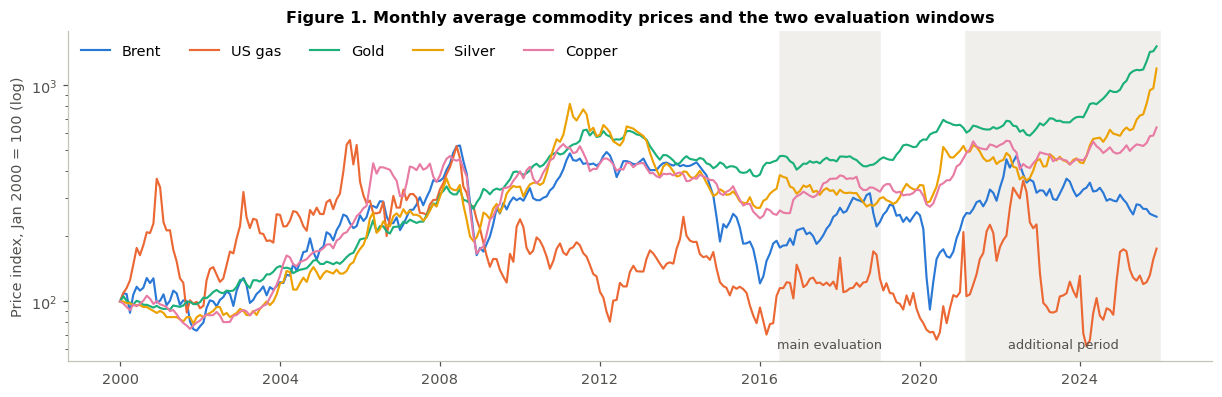

In [4]:
summary = pd.DataFrame({"mean, % p.a.": 100 * ret.mean() * 12, "volatility, % p.a.": 100 * ret.std() * np.sqrt(12),
                        "worst month, %": 100 * ret.min(), "autocorr. lag 1": ret.apply(lambda s: s.autocorr(1)),
                        "autocorr. lag 2": ret.apply(lambda s: s.autocorr(2))})
print("Table 1. Monthly price changes, Jan 2000 - Dec 2025, with their correlations")
show(summary.join(log_ret.corr().add_prefix("corr. ")))

fig, ax = plt.subplots(figsize=(11, 3.5), layout="constrained")
for (name, s), color in zip((100 * prices / prices.iloc[0]).items(), ASSET_COLORS):
    ax.plot(s.index, s, color=color, lw=1.4, label=name)
for lo, hi, tag in [("2016-07-01", "2018-12-31", "main evaluation"), ("2021-03-01", "2025-12-31", "additional period")]:
    ax.axvspan(pd.Timestamp(lo), pd.Timestamp(hi), color="#f0efec", zorder=0)
    ax.text(pd.Timestamp(lo) + (pd.Timestamp(hi) - pd.Timestamp(lo)) / 2, 0.04, tag, ha="center", fontsize=8.5,
            color="#52514e", transform=ax.get_xaxis_transform())
ax.set(yscale="log", ylabel="Price index, Jan 2000 = 100 (log)",
       title="Figure 1. Monthly average commodity prices and the two evaluation windows")
ax.legend(ncol=5, loc="upper left")
plt.show()

Gold has by far the lowest volatility (13% a year, against 21–54% for the other four commodities) and a high average return. A mean–variance optimiser will therefore hold a lot of it. Gold and silver move together (correlation 0.75), copper is linked to Brent and silver (0.46–0.48), and US gas is almost unrelated to the rest. Four of the five commodities have positive lag-1 autocorrelation, while lag-2 values are close to zero (largest 0.14, for copper). This is the averaging effect discussed in Section 3.1. Figure 1 shows how different the two evaluation windows are. 2016–2018 is a calm, range-bound market, whereas 2021–2025 includes the 2022 energy shock and a strong rally in gold and silver.

Label shares: positive 41.3%, negative 36.0%, neutral 3.7%, none 19.0% | headlines per month 14-250 (median 44) | describing past moves: 96.7%, looking ahead: 3.3%
Monthly sentiment S_t: mean 0.073, sd 0.206, range -0.38 to 0.53; correlation with the same month's gold change 0.43


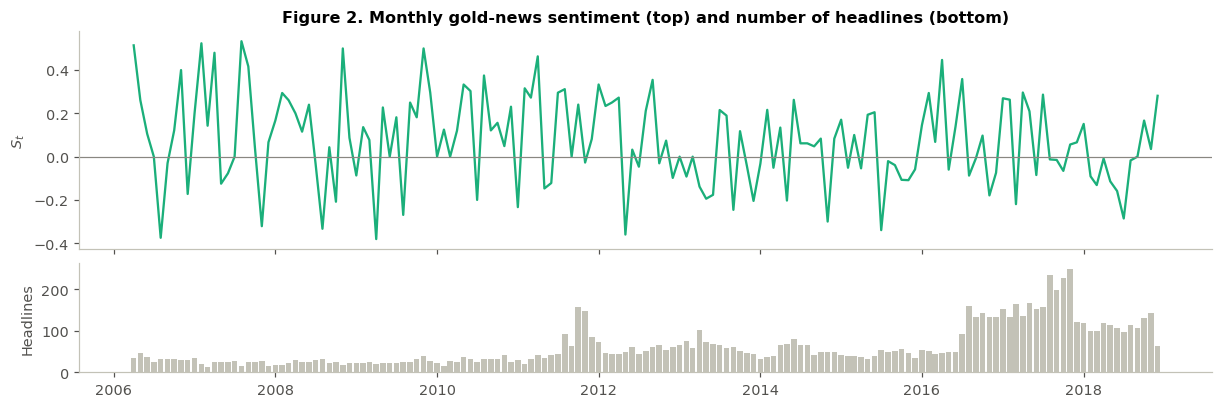

In [5]:
share = label_counts.sum() / label_counts.sum().sum()
print("Label shares: " + ", ".join(f"{k} {v:.1%}" for k, v in share.items())
      + f" | headlines per month {headlines.min()}-{headlines.max()} (median {headlines.median():.0f})"
      + f" | describing past moves: {news['Past Information'].mean():.1%}, looking ahead: {news['Future Information'].mean():.1%}")
print(f"Monthly sentiment S_t: mean {sentiment.mean():.3f}, sd {sentiment.std():.3f}, range {sentiment.min():.2f} to {sentiment.max():.2f}; "
      f"correlation with the same month's gold change {sentiment.corr(ret.Gold.reindex(sentiment.index)):.2f}")

fig, ax = plt.subplots(2, 1, figsize=(11, 3.6), sharex=True, layout="constrained", height_ratios=[2, 1])
ax[0].plot(sentiment.index, sentiment, color=OTHER_COLOR["News only"])
ax[0].axhline(0, color="#898781", lw=0.8)
ax[0].set(ylabel="$S_t$", title="Figure 2. Monthly gold-news sentiment (top) and number of headlines (bottom)")
ax[1].bar(headlines.index, headlines, width=25, color="#c3c2b7")
ax[1].set(ylabel="Headlines")
plt.show()

Positive and negative labels dominate (41% and 36%), and 19% of headlines carry no price direction. Coverage is uneven, from 14 to 250 headlines a month, with many more in 2016–2017, so the index is noisier in the early years. The key fact for H2 is that 97% of headlines report moves that have already happened ("gold falls on strong dollar"), and $S_t$ has a correlation of 0.43 with gold's change in the same month. Sentiment may therefore mostly repeat what prices already show. Section 4.3 tests whether anything is left at horizons a strategy can use.

## 3. Methodology and experimental design

### 3.1 Experimental protocol

Models are selected and fitted on past data only, then **frozen**. Portfolios are then rebuilt every month, walking forward through the evaluation period:

| | Main experiment (A) | Additional period (B) |
|:--|:--|:--|
| Training / validation | Apr 2006 – Dec 2012 / Jan 2013 – Dec 2015 | Apr 2006 – Dec 2015 / Jan 2016 – Dec 2020 |
| Models frozen at | Dec 2015 | Dec 2020 |
| Portfolio evaluation | Jul 2016 – Dec 2018 (30 months) | Mar 2021 – Dec 2025 (58 months) |
| Questions | H1, H2, H3, FRED | H1, FRED |

The two periods are separate experiments, and their results are never pooled.

**Information lag.** The decision for month $t$ uses data up to month $c=t-2$ only. Month $c$'s average is published early in month $c+1$, so this leaves time for publication and collection. It also matters for a statistical reason. Changes in monthly *averages* are autocorrelated at lag 1 even for a random walk (Working, 1960; see Table 1). A one-month lag would therefore create spurious predictability, because the return of month $t$ is measured from the average of month $t-1$. Evaluation starts in July 2016 (rather than January) because the first decision needs 120 past returns, each paired with a regime observed two months earlier, all after April 2006. Evaluation B starts in March 2021, the first month whose information cut-off (January 2021) falls after the models are frozen.

**Preventing look-ahead.** Scalers, cluster models, the number of states and the sentiment threshold use only training or development data. Features use backward-looking windows only. Portfolio settings were fixed beforehand and not tuned. Section 3.5 checks these properties in code.

In [6]:
EXPERIMENTS = {
    "A": dict(train_end="2012-12-01", model_end="2015-12-01", first="2016-07-01", last="2018-12-01",
              feature_sets=["price", "price+FRED", "price+news", "price+FRED+news"]),
    "B": dict(train_end="2015-12-01", model_end="2020-12-01", first="2021-03-01", last="2025-12-01",
              feature_sets=["price", "price+FRED"]),
}
for cfg in EXPERIMENTS.values():
    for key in ["train_end", "model_end", "first", "last"]:
        cfg[key] = pd.Timestamp(cfg[key])
    cfg["dates"] = pd.date_range(cfg["first"], cfg["last"], freq="MS")
    cfg["signals"] = cfg["dates"] - pd.DateOffset(months=LAG)    # information cut-off of each decision

### 3.2 Market regime detection

Regimes are found by **clustering months** on standardised features. No "true regime" label exists, so this is unsupervised learning, and it differs from classification: the clusters are only useful if they line up with differences in later returns or risk, which is what the portfolio test checks.

* **KMeans** assigns each month to its nearest centroid, so a month belongs to exactly one state.
* **GMM** fits a mixture of Gaussians with diagonal covariances and returns membership probabilities $p_{t,j}$. A month can therefore lie between two states.

**Scaling and selection.** For each feature set, $k\in\{2,3,4\}$ is fixed before any portfolio is evaluated. The scaler and the candidate models are fitted on training months. KMeans takes the $k$ with the highest **silhouette on validation months**, and the GMM the $k$ with the lowest **BIC on training months**. Both are then refitted on all development months (training plus validation) and frozen. States are numbered from the weakest (0) to the strongest average commodity return in the development sample. This is only for readability and does not affect any portfolio.

**Interpretation and stability.** We describe each state with development-sample averages. We measure stability with the adjusted Rand index (ARI, where 1 means identical partitions up to relabelling) across random seeds, between the two algorithms, and between the two experiments' fits.

In [7]:
market_move = log_ret.mean(axis=1)            # average commodity log change, used only to order the states

def make_model(alg, k, n_init, seed=SEED):
    if alg == "KMeans":
        return KMeans(n_clusters=k, n_init=n_init, random_state=seed)
    return GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4, n_init=n_init, max_iter=500, random_state=seed)

def select_k(X, train, valid):
    """KMeans: best validation silhouette. GMM: lowest training BIC. Scaler fitted on training months only."""
    scaler = StandardScaler().fit(X.loc[train])
    z_train, z_valid = scaler.transform(X.loc[train]), scaler.transform(X.loc[valid])
    rows = []
    for k in K_GRID:
        groups = make_model("KMeans", k, 30).fit(z_train).predict(z_valid)
        gmm = make_model("GMM", k, 10).fit(z_train)
        assert gmm.converged_
        n_groups = len(np.unique(groups))
        rows.append({"k": k, "silhouette": silhouette_score(z_valid, groups) if 1 < n_groups < len(groups) else np.nan,
                     "groups": n_groups, "BIC": gmm.bic(z_train)})
    table = pd.DataFrame(rows).set_index("k")
    return {"KMeans": int(table.silhouette.idxmax()), "GMM": int(table.BIC.idxmin())}, table

def fit_regimes(X, alg, k, dev, seed=SEED):
    """Fit scaler and model on development months; return state memberships for every month, states ordered by return."""
    scaler = StandardScaler().fit(X.loc[dev])
    model = make_model(alg, k, 50 if alg == "KMeans" else 20, seed).fit(scaler.transform(X.loc[dev]))
    if alg == "GMM":
        assert model.converged_
    z = scaler.transform(X)
    p = pd.DataFrame(np.eye(k)[model.predict(z)] if alg == "KMeans" else model.predict_proba(z), index=X.index)
    w = p.loc[dev]
    p = p[(w.mul(market_move.loc[dev], axis=0).sum() / w.sum()).sort_values().index]
    p.columns = range(k)
    return p

def hard(p):
    return pd.Series(p.to_numpy().argmax(axis=1), index=p.index)

regimes, selection, chosen_k = {}, {}, {}
for exp, cfg in EXPERIMENTS.items():
    for fs in cfg["feature_sets"]:
        X = FEATURES[fs].loc[:cfg["last"]]
        train = X.index[X.index <= cfg["train_end"]]
        valid = X.index[(X.index > cfg["train_end"]) & (X.index <= cfg["model_end"])]
        dev = X.index[X.index <= cfg["model_end"]]
        chosen, selection[(exp, fs)] = select_k(X, train, valid)
        for alg in ["KMeans", "GMM"]:
            chosen_k[(exp, alg, fs)] = chosen[alg]
            regimes[(exp, alg, fs)] = fit_regimes(X, alg, chosen[alg], dev)

### 3.3 News sentiment

$S_t$ (Section 2.2) measures the balance of positive and negative gold-price headlines in month $t$. Because most headlines report moves that have already happened (Section 2.3), we treat it as a measure of recent market tone rather than as a forecast. Sentiment enters the allocation in two ways:

* **Sentiment-only (H2).** Two states: $S_t$ above or below its development-sample median (Apr 2006 – Dec 2015), fixed before the evaluation. The states then condition Markowitz exactly like KMeans regimes.
* **Combined (H3).** $S_t$ is added as an extra clustering feature, so KMeans and the GMM see the price features plus sentiment ("price+news"), or the price, FRED and sentiment features ("price+FRED+news"). The number of states is selected with the same rule as for every other feature set.

In [8]:
news_threshold = sentiment.loc[:EXPERIMENTS["A"]["model_end"]].median()
news_states = pd.DataFrame(np.eye(2)[(sentiment > news_threshold).astype(int)], index=sentiment.index)
print(f"Sentiment threshold (development median): {news_threshold:.3f}")

Sentiment threshold (development median): 0.081


### 3.4 Portfolio construction

At each decision month $t$ (cut-off $c=t-2$), every strategy uses the same window of 120 monthly returns $r_u$, $u=c-119,\dots,c$.

* **Equal weight:** 20% per asset, rebalanced monthly. No estimation.
* **Classical Markowitz:** sample mean $\mu_0$ and covariance $\Sigma_0$ of the window.
* **Regime-, sentiment- and combined-conditioned Markowitz.** These three differ only in the membership vectors $p$ they use. Each past return $r_u$ is paired with the state observable two months earlier, $p_{u-2}$, the same lag as the live decision. For each state $j$ we compute moments weighted by $a_{u,j}=p_{u-2,j}$, with effective sample size $n_j=(\sum_u a_{u,j})^2/\sum_u a_{u,j}^2$. When $n_j<12$, the state uses the unconditional moments $(\mu_0,\Sigma_0)$. Otherwise, it is blended with them using weight $\alpha_j=n_j/(n_j+24)$ on the state estimate, so that small states cannot drive the allocation. The state moments are then mixed with the current membership $p_c$:
$$\mu=\sum_j p_{c,j}\,\mu_j,\qquad \Sigma=\sum_j p_{c,j}\left(\Sigma_j+\mu_j\mu_j^\top\right)-\mu\mu^\top ,$$
which keeps the spread between state means in the covariance.

**Risk estimation, constraints and costs.** For every optimised strategy, we halve the mean, $\hat\mu=0.5\mu$, shrink the covariance 20% towards its diagonal, and solve
$$\max_w\; w^\top\hat\mu-\tfrac{\gamma}{2}\,w^\top\hat\Sigma w\quad\text{s.t.}\quad \mathbf 1^\top w=1,\; 0\le w_i\le 0.6,\qquad \gamma=5 .$$
These settings were fixed in the team's earlier work (Notebook 02) and are not tuned. Between rebalances, weights drift with returns: $\tilde w_{i,t}=w_{i,t-1}(1+r_{i,t-1})/(1+w_{t-1}^\top r_{t-1})$. Turnover is $TO_t=\sum_i|w_{i,t}-\tilde w_{i,t}|$, counting both buys and sells, and the first month starts from cash. The net return is
$$R_t=(1-0.001\,TO_t)(1+w_t^\top r_t)-1,$$
i.e. 10 bp per unit of two-sided turnover, or 20 bp under the course's one-sided convention.

In [9]:
def moments(R, a=None):
    p = np.full(len(R), 1 / len(R)) if a is None else a / a.sum()
    mu = p @ R
    centred = R - mu
    return mu, (centred * p[:, None]).T @ centred

def regularise(mu, cov):
    cov = (1 - COV_SHRINK) * cov + COV_SHRINK * np.diag(np.diag(cov))
    return (1 - MEAN_SHRINK) * mu, (cov + cov.T) / 2 + 1e-8 * np.eye(len(mu))

def optimise(mu, cov):
    n = len(mu)
    res = minimize(lambda w: GAMMA / 2 * w @ cov @ w - w @ mu, np.full(n, 1 / n), jac=lambda w: GAMMA * cov @ w - mu,
                   method="SLSQP", bounds=[(0, CAP)] * n, options={"ftol": 1e-12, "maxiter": 500},
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)})
    if not res.success:
        raise RuntimeError(res.message)
    return res.x

def regime_moments(R, p_hist, p_now):
    """State-conditional moments shrunk towards the window's unconditional moments, mixed by current membership."""
    mu0, cov0 = moments(R)
    means, seconds = [], []
    for a in p_hist.T:
        n_eff = a.sum() ** 2 / (a @ a) if a @ a > 0 else 0.0
        if n_eff < MIN_EFFECTIVE:
            mu_j, second_j = mu0, cov0 + np.outer(mu0, mu0)
        else:
            mu_c, cov_c = moments(R, a)
            alpha = n_eff / (n_eff + PRIOR)
            mu_j = alpha * mu_c + (1 - alpha) * mu0
            second_j = alpha * (cov_c + np.outer(mu_c, mu_c)) + (1 - alpha) * (cov0 + np.outer(mu0, mu0))
        means.append(mu_j)
        seconds.append(second_j)
    mu = p_now @ np.array(means)
    return mu, np.tensordot(p_now, np.array(seconds), axes=1) - np.outer(mu, mu)

def allocate(memberships, dates, model_end, returns=ret):
    """Walk-forward target weights. Only data up to c = t - LAG enters the decision for month t."""
    W = {name: [] for name in ["Equal weight", "Markowitz", *memberships]}
    for t in dates:
        c = t - pd.DateOffset(months=LAG)
        hist = returns.loc[:c].tail(LOOKBACK)
        assert c > model_end and len(hist) == LOOKBACK and hist.index[-1] == c
        R, past_signals = hist.to_numpy(), hist.index - pd.DateOffset(months=LAG)   # r_u is paired with the state at u-2
        W["Equal weight"].append(np.full(R.shape[1], 1 / R.shape[1]))
        W["Markowitz"].append(optimise(*regularise(*moments(R))))
        for name, p in memberships.items():
            W[name].append(optimise(*regularise(*regime_moments(R, p.loc[past_signals].to_numpy(), p.loc[c].to_numpy()))))
    W = {k: pd.DataFrame(v, index=dates, columns=returns.columns) for k, v in W.items()}
    for w in W.values():
        assert np.allclose(w.sum(axis=1), 1) and w.min().min() > -1e-8 and w.max().max() < CAP + 1e-8
    return W

def backtest(w, fee_bps=FEE_BPS):
    held, rows = np.zeros(w.shape[1]), []
    for t, target in w.iterrows():
        r = ret.loc[t].to_numpy()
        turnover = np.abs(target.to_numpy() - held).sum()
        gross = target.to_numpy() @ r
        rows.append((gross, (1 - fee_bps / 1e4 * turnover) * (1 + gross) - 1, turnover))
        held = target.to_numpy() * (1 + r) / (1 + gross)        # drifted weights before the next rebalance
    return pd.DataFrame(rows, index=w.index, columns=["gross", "net", "turnover"])

### 3.5 Evaluation

We report net CAGR, annualised volatility $\sqrt{12}\,s_R$, maximum drawdown (largest fall from a previous peak of wealth, including the starting value), turnover, and the annualised Sharpe ratio $SR=\sqrt{12}\,\bar R/s_R$ with a zero risk-free rate for every strategy. Lo's (2002) approximate standard error, $\mathrm{SE}(SR)\approx\sqrt{12\,(1+SR_m^2/2)/T}$ with $SR_m$ the monthly Sharpe ratio, shows how imprecise a Sharpe ratio is over 30 or 58 months.

Each hypothesis is a **paired comparison** between two strategies that differ in one ingredient only. We estimate the Sharpe-ratio difference and its 95% interval with a circular block bootstrap: 1,000 resamples of six-month blocks, with the same months drawn for both strategies. This keeps their correlation and some serial dependence. The intervals hold the fitted models fixed and rely on only 5–10 blocks per resample. We compute 19 such comparisons, so about one interval would exclude zero by chance even if nothing worked. We therefore read an interval that excludes zero as a signal to examine, not as proof. Robustness checks (Section 5.1) vary costs, block length and the number of states without using them to select a model.

The next cells run all strategies and then check the implementation: (1) replacing all data after each decision's cut-off with random values must leave the weights unchanged; (2) features computed from truncated price histories must equal the full-sample features; (3) a vectorised recomputation of net returns must match the backtest loop.

In [10]:
STRATEGY_ORDER = ["Equal weight", "Markowitz"] + [f"{a} · {f}" for f in ["price", "price+FRED"] for a in ["KMeans", "GMM"]] \
                 + ["News only"] + [f"{a} · {f}" for f in ["price+news", "price+FRED+news"] for a in ["KMeans", "GMM"]]

def memberships(exp):
    m = {f"{alg} · {fs}": regimes[(exp, alg, fs)] for fs in EXPERIMENTS[exp]["feature_sets"] for alg in ["KMeans", "GMM"]}
    if exp == "A":
        m["News only"] = news_states
    return m

results = {}
for exp, cfg in EXPERIMENTS.items():
    W = allocate(memberships(exp), cfg["dates"], cfg["model_end"])
    order = [s for s in STRATEGY_ORDER if s in W]
    paths = {s: backtest(W[s]) for s in order}
    results[exp] = dict(weights={s: W[s] for s in order}, paths=paths, net=pd.DataFrame({s: paths[s].net for s in order}))

def sharpe(x):
    return np.sqrt(12) * x.mean() / x.std(ddof=1)

def performance(exp):
    rows = {}
    for s, path in results[exp]["paths"].items():
        wealth, sr, T = np.r_[1.0, (1 + path.net).cumprod()], sharpe(path.net), len(path)
        rows[s] = {"Sharpe": sr, "SE (Lo)": np.sqrt(12 * (1 + sr ** 2 / 24) / T), "CAGR": wealth[-1] ** (12 / T) - 1,
                   "volatility": path.net.std() * np.sqrt(12), "max drawdown": (wealth / np.maximum.accumulate(wealth) - 1).min(),
                   "turnover / month": path.turnover.mean(), "gold weight": results[exp]["weights"][s]["Gold"].mean()}
    return pd.DataFrame(rows).T

def contrasts(net, pairs, block=6, reps=1000, seed=SEED):
    """Paired circular block bootstrap of Sharpe-ratio differences (same resampled months for both strategies)."""
    n, rng = len(net), np.random.default_rng(seed)
    idx = np.stack([np.concatenate([(s + np.arange(block)) % n for s in rng.integers(0, n, int(np.ceil(n / block)))])[:n]
                    for _ in range(reps)])
    X = net.to_numpy()[idx]
    draws = pd.DataFrame(np.sqrt(12) * X.mean(axis=1) / X.std(axis=1, ddof=1), columns=net.columns)
    observed = sharpe(net)
    return pd.DataFrame({label: {"ΔSharpe": observed[a] - observed[b], "95% low": (draws[a] - draws[b]).quantile(0.025),
                                 "95% high": (draws[a] - draws[b]).quantile(0.975)} for label, (a, b) in pairs.items()}).T

perf = {exp: performance(exp) for exp in EXPERIMENTS}
PCT = {c: "{:.1%}" for c in ["CAGR", "volatility", "max drawdown", "turnover / month", "gold weight"]}

In [11]:
rng = np.random.default_rng(2026)
for exp, cfg in EXPERIMENTS.items():                                   # (1) no look-ahead in any decision
    for t in cfg["dates"]:
        c = t - pd.DateOffset(months=LAG)
        fake_ret = ret.copy()
        fake_ret.loc[fake_ret.index > c] = rng.uniform(-0.4, 0.5, size=((fake_ret.index > c).sum(), ret.shape[1]))
        fake = {}
        for s, p in memberships(exp).items():
            fake[s] = p.copy()
            fake[s].loc[p.index > c] = rng.dirichlet(np.ones(p.shape[1]), (p.index > c).sum())
        replay = allocate(fake, pd.DatetimeIndex([t]), cfg["model_end"], returns=fake_ret)
        for s in replay:
            np.testing.assert_allclose(replay[s].loc[t], results[exp]["weights"][s].loc[t], atol=1e-10)
for cut in ["2012-06-01", "2016-05-01", "2020-12-01"]:                 # (2) features are causal
    lr_cut = np.log(prices.loc[:cut]).diff().dropna()
    f_cut = pd.concat({"ret": lr_cut, "mom3": lr_cut.rolling(3).sum(), "vol12": lr_cut.rolling(12).std() * np.sqrt(12)}, axis=1)
    f_cut.columns = price_feat.columns
    pd.testing.assert_frame_equal(f_cut.loc[SAMPLE_START:], price_feat.loc[SAMPLE_START:cut])
for exp in EXPERIMENTS:                                                # (3) cash flows reconcile
    for s, w in results[exp]["weights"].items():
        r = ret.loc[w.index]
        gross = (w * r).sum(axis=1)
        drifted = (w * (1 + r)).div(1 + gross, axis=0).shift(1).fillna(0)
        net = (1 - FEE_BPS / 1e4 * (w - drifted).abs().sum(axis=1)) * (1 + gross) - 1
        np.testing.assert_allclose(results[exp]["net"][s], net, atol=1e-12)
print(f"PASS: no look-ahead in {sum(len(c['dates']) for c in EXPERIMENTS.values())} decision months, causal features, "
      "cash flows reconcile.")

PASS: no look-ahead in 88 decision months, causal features, cash flows reconcile.


## 4. Empirical results

### 4.1 Market regime identification

In [12]:
sel = pd.DataFrame({(exp, fs): {**{f"silhouette k={k}": "–" if np.isnan(t.loc[k, "silhouette"]) else
                                   f"{t.loc[k, 'silhouette']:.3f} ({t.loc[k, 'groups']})" for k in K_GRID},
                                **{f"BIC k={k}": f"{t.loc[k, 'BIC']:.0f}" for k in K_GRID},
                                "chosen k: KMeans / GMM": f"{chosen_k[(exp, 'KMeans', fs)]} / {chosen_k[(exp, 'GMM', fs)]}"}
                    for (exp, fs), t in selection.items()}).T.rename_axis(["experiment", "features"])
print("Table 2. Model selection. KMeans: validation silhouette (clusters actually used by the validation months). GMM: training BIC.")
display(sel)

Table 2. Model selection. KMeans: validation silhouette (clusters actually used by the validation months). GMM: training BIC.


silhouette k=2 silhouette k=3 silhouette k=4  \
experiment features                                                       
A          price                0.070 (2)      0.171 (2)      0.170 (2)   
           price+FRED           0.162 (2)      0.173 (2)              –   
           price+news           0.043 (2)      0.161 (2)      0.152 (2)   
           price+FRED+news      0.164 (2)              –              –   
B          price                0.154 (2)      0.286 (3)      0.145 (4)   
           price+FRED           0.159 (2)      0.219 (3)      0.254 (3)   

                           BIC k=2 BIC k=3 BIC k=4 chosen k: KMeans / GMM  
experiment features                                                        
A          price              3297    3290    3242                  3 / 4  
           price+FRED         4654    4448    4443                  3 / 4  
           price+news         3543    3532    3494                  3 / 4  
           price+FRED+news    4899    4829    4688                  2 / 4  
B          price              4809    4591    4590                  3 / 4  
           price+FRED         6759    6407    6231                  4 / 4

The clusters are weakly separated. With a silhouette between 0.04 and 0.29, a month is only slightly closer to its own centroid than to the next one. In the main experiment, the 2013–2015 validation months use at most two KMeans clusters whatever $k$ is. For price+FRED+news, three or four clusters collapse into one (undefined silhouette), which is why that feature set gets $k=2$. Some choices are near ties, for example 0.171 against 0.170 for price-only KMeans. BIC keeps decreasing up to the largest value we allow, so the GMM always takes $k=4$: the grid sets the limit, not the data. We keep the rules fixed in advance, and Section 5.1 shows how much $k$ matters.

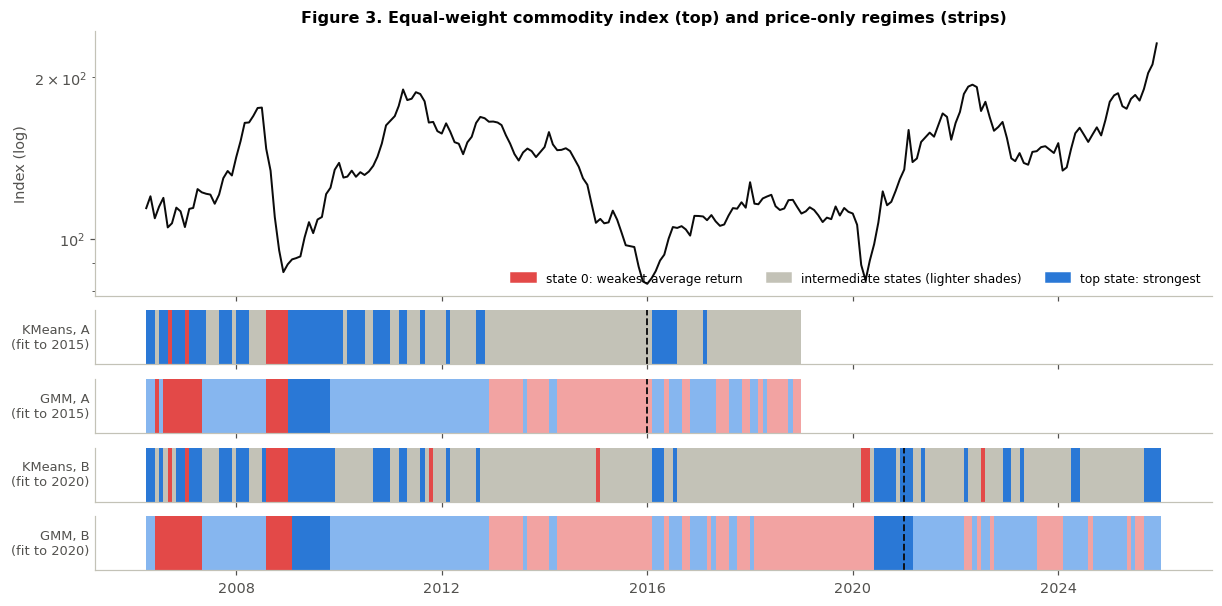

Do the regimes survive five more years of data? ARI between the A fit (to 2015) and the B fit (to 2020) on Apr 2006 - Dec 2015: KMeans 0.64, GMM 0.97


In [13]:
STATE_COLORS = {2: ["#e34948", "#2a78d6"], 3: ["#e34948", "#c3c2b7", "#2a78d6"], 4: ["#e34948", "#f2a3a2", "#86b6ef", "#2a78d6"]}
strips = [(e, a) for e in ["A", "B"] for a in ["KMeans", "GMM"]]
basket = 100 * np.exp(market_move.loc[SAMPLE_START:].cumsum())
fig, axes = plt.subplots(1 + len(strips), 1, figsize=(11, 5.4), sharex=True, layout="constrained",
                         height_ratios=[2.2] + [0.45] * len(strips))
axes[0].plot(basket.index, basket, color="#0b0b0b", lw=1.3)
axes[0].set(ylabel="Index (log)", yscale="log", title="Figure 3. Equal-weight commodity index (top) and price-only regimes (strips)")
for ax, (exp, alg) in zip(axes[1:], strips):
    p = regimes[(exp, alg, "price")]
    edges = np.append(mdates.date2num(p.index), mdates.date2num(p.index[-1] + pd.DateOffset(months=1)))
    for i, s in enumerate(hard(p)):
        ax.axvspan(edges[i], edges[i + 1], color=STATE_COLORS[p.shape[1]][s], lw=0)
    ax.axvline(EXPERIMENTS[exp]["model_end"] + pd.DateOffset(months=1), color="#0b0b0b", lw=1.2, ls="--")
    ax.set_yticks([]); ax.grid(False)
    ax.set_ylabel(f"{alg}, {exp}\n(fit to {EXPERIMENTS[exp]['model_end']:%Y})", rotation=0, ha="right", va="center", fontsize=8.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#e34948", "#c3c2b7", "#2a78d6"]]
axes[0].legend(handles, ["state 0: weakest average return", "intermediate states (lighter shades)", "top state: strongest"],
               ncol=3, loc="lower right", fontsize=8)
plt.show()
overlap = pd.date_range(SAMPLE_START, EXPERIMENTS["A"]["model_end"], freq="MS")
print("Do the regimes survive five more years of data? ARI between the A fit (to 2015) and the B fit (to 2020) on Apr 2006 - Dec 2015: "
      + ", ".join(f"{a} {adjusted_rand_score(hard(regimes[('A', a, 'price')]).loc[overlap], hard(regimes[('B', a, 'price')]).loc[overlap]):.2f}"
                  for a in ["KMeans", "GMM"]))

Both algorithms put the late-2008 collapse in their weakest state (red) and the 2009–2010 recovery in their strongest (blue). KMeans fitted to 2020 also places the spring 2020 sell-off in the weakest state. Between these episodes, KMeans puts most calm months into a single middle state. The GMM splits them into a mildly rising period (2010–2012) and a drifting one (2013–2020). Adding five more years of data barely changes the GMM partition (ARI 0.97 on 2006–2015) but changes KMeans more (0.64). In the main evaluation window the models use few states. KMeans puts 26 of the 30 signals in its middle state, and the GMM alternates between its two intermediate states (Table 4). For H1, the regime information is therefore essentially a two-way split.

In [14]:
profile_vars = pd.DataFrame({"commodity change, %/m": 100 * market_move, "12m volatility": price_feat.filter(like="vol12").mean(axis=1),
                             "VIX": fred.VIXCLS, "10y-2y slope": macro_feat["10y-2y slope"],
                             "basket at t+2, %": 100 * ret.mean(axis=1).shift(-LAG)})

def state_profile(models, cols):
    rows = []
    for exp, alg, fs in models:
        cfg, p = EXPERIMENTS[exp], regimes[(exp, alg, fs)]
        lab = hard(p)
        dev, sig = lab.loc[:cfg["model_end"]], lab.loc[cfg["signals"]]
        for j in range(p.shape[1]):
            d, e = profile_vars.loc[dev.index[dev == j]], profile_vars.loc[sig.index[sig == j]]
            rows.append({"model": f"{exp}: {alg} · {fs}", "state": j, "dev. months": len(d), **d[cols].mean().to_dict(),
                         "basket at t+2, dev. %": d["basket at t+2, %"].mean(), "eval. months": len(e),
                         "basket at t+2, eval. %": e["basket at t+2, %"].mean()})
    return pd.DataFrame(rows).set_index(["model", "state"])

print("Table 3. State profiles of the price-only models: development averages, and the average basket return two months later")
show(state_profile([(e, a, "price") for e, a in strips], ["commodity change, %/m", "12m volatility", "VIX"]),
     **{"dev. months": "{:.0f}", "eval. months": "{:.0f}", "VIX": "{:.1f}"})

Table 3. State profiles of the price-only models: development averages, and the average basket return two months later


dev. months commodity change, %/m 12m volatility  \
model             state                                                    
A: KMeans · price 0               7                -12.87           0.37   
                  1              66                 -1.61           0.22   
                  2              44                  4.05           0.32   
A: GMM · price    0              15                 -4.83           0.37   
                  1              34                 -2.20           0.20   
                  2              58                  1.64           0.25   
                  3              10                  3.35           0.41   
B: KMeans · price 0              11                -11.93           0.33   
                  1             121                 -0.39           0.23   
                  2              45                  4.53           0.32   
B: GMM · price    0              17                 -3.78           0.37   
                  1              73                 -1.55           0.21   
                  2              71                  1.94           0.25   
                  3              16                  4.07           0.39   

                          VIX basket at t+2, dev. % eval. months  \
model             state                                            
A: KMeans · price 0      35.8                 -3.38            0   
                  1      17.8                 -0.43           26   
                  2      22.4                  1.34            4   
A: GMM · price    0      23.5                 -0.67            0   
                  1      15.1                 -1.61           14   
                  2      20.9                  0.47           16   
                  3      33.5                  4.43            0   
B: KMeans · price 0      36.5                 -1.08            1   
                  1      16.7                 -0.04           46   
                  2      23.2                  2.56           11   
B: GMM · price    0      24.3                 -1.19            0   
                  1      16.3                 -0.37           14   
                  2      19.6                  0.77           42   
                  3      29.7                  5.73            2   

                        basket at t+2, eval. %  
model             state                         
A: KMeans · price 0                          –  
                  1                       0.54  
                  2                       2.01  
A: GMM · price    0                          –  
                  1                       1.85  
                  2                      -0.23  
                  3                          –  
B: KMeans · price 0                      -6.40  
                  1                       1.60  
                  2                      -0.02  
B: GMM · price    0                          –  
                  1                       1.44  
                  2                       1.31  
                  3                      -4.15

The states have a clear economic reading, and it is similar across the two fits. There is a rare sell-off state (about −12% a month for KMeans, VIX near 36), a large calm state (VIX 16–18) and a rally state (+4% a month) with higher volatility. The GMM splits the middle further. In the development years, the basket return two months later rises with the state. After a KMeans rally state it averaged +1.3% (A fit) and +2.6% (B fit), against −3.4% and −1.1% after a sell-off. A regime-conditioned optimiser is designed to exploit this short-term momentum.

Out of sample, the pattern held only partly. In 2016–2018, KMeans' rally state was followed by +2.0%, against +0.5% for the calm state, but this rests on only four months. The GMM's ordering reversed: +1.9% after its lower intermediate state, −0.2% after the higher one. In 2021–2025, KMeans' rally state was followed by a flat basket (11 months), and the calm state by +1.6%. These samples are small, but they show why a relationship estimated on 2006–2015 may not pay off afterwards.

In [15]:
diag_rows = []
for (exp, alg, fs), p in regimes.items():
    cfg = EXPERIMENTS[exp]
    X = FEATURES[fs].loc[:cfg["last"]]
    dev = X.index[X.index <= cfg["model_end"]]
    lab, k = hard(p), p.shape[1]
    sig = lab.loc[cfg["signals"]]
    seeds = [adjusted_rand_score(lab.loc[dev], hard(fit_regimes(X, alg, k, dev, seed)).loc[dev]) for seed in [0, 7, 21, 99]]
    other = hard(regimes[(exp, "GMM" if alg == "KMeans" else "KMeans", fs)])
    diag_rows.append({"experiment": exp, "features": fs, "model": alg, "k": k,
                      "dev. months per state": ", ".join(str(int((lab.loc[dev] == j).sum())) for j in range(k)),
                      "eval. months per state": ", ".join(str(int((sig == j).sum())) for j in range(k)),
                      "persistence": (sig.values[1:] == sig.values[:-1]).mean(),
                      "top membership": p.loc[cfg["signals"]].max(axis=1).mean(),
                      "KMeans-GMM ARI": adjusted_rand_score(lab.loc[dev], other.loc[dev]),
                      "seed ARI (min)": min(seeds)})
diagnostics = pd.DataFrame(diag_rows).set_index(["experiment", "features", "model"])
print("Table 4. Regime diagnostics for all twelve models. Persistence and top membership (mean of max_j p_tj) are measured on "
      "evaluation signals; ARIs on development months; seed ARI uses seeds 0, 7, 21, 99.")
show(diagnostics, k="{:.0f}")

Table 4. Regime diagnostics for all twelve models. Persistence and top membership (mean of max_j p_tj) are measured on evaluation signals; ARIs on development months; seed ARI uses seeds 0, 7, 21, 99.


k dev. months per state  \
experiment features        model                             
A          price           KMeans  3             7, 66, 44   
                           GMM     4        15, 34, 58, 10   
           price+FRED      KMeans  3             4, 62, 51   
                           GMM     4        53, 12, 12, 40   
           price+news      KMeans  3             7, 59, 51   
                           GMM     4        18, 27, 42, 30   
           price+FRED+news KMeans  2                61, 56   
                           GMM     4        52, 12, 12, 41   
B          price           KMeans  3           11, 121, 45   
                           GMM     4        17, 73, 71, 16   
           price+FRED      KMeans  4       18, 15, 102, 42   
                           GMM     4        20, 90, 17, 50   

                                  eval. months per state persistence  \
experiment features        model                                       
A          price           KMeans               0, 26, 4        0.90   
                           GMM              0, 14, 16, 0        0.62   
           price+FRED      KMeans               0, 26, 4        0.79   
                           GMM              18, 0, 0, 12        0.62   
           price+news      KMeans               0, 22, 8        0.76   
                           GMM              2, 0, 17, 11        0.52   
           price+FRED+news KMeans                  22, 8        0.69   
                           GMM              18, 0, 0, 12        0.62   
B          price           KMeans              1, 46, 11        0.75   
                           GMM              0, 14, 42, 2        0.74   
           price+FRED      KMeans           1, 20, 28, 9        0.60   
                           GMM              2, 23, 1, 32        0.65   

                                  top membership KMeans-GMM ARI seed ARI (min)  
experiment features        model                                                
A          price           KMeans           1.00           0.23           0.82  
                           GMM              0.91           0.23           0.40  
           price+FRED      KMeans           1.00           0.51           0.93  
                           GMM              0.93           0.51           0.63  
           price+news      KMeans           1.00           0.36           0.70  
                           GMM              0.91           0.36           0.27  
           price+FRED+news KMeans           1.00           0.49           1.00  
                           GMM              0.95           0.49           0.47  
B          price           KMeans           1.00           0.26           0.84  
                           GMM              0.93           0.26           0.48  
           price+FRED      KMeans           1.00           0.63           0.81  
                           GMM              0.93           0.63           0.92

* **The two algorithms find different regimes.** Their agreement on development months is low (ARI 0.23–0.63), and lowest with price-only features.
* **KMeans is stable across seeds, the GMM is not.** The minimum ARI across seeds is 0.70–1.00 for KMeans and 0.27–0.92 for the GMM, so a GMM result can change just because of the random start. With the seed fixed, however, the GMM finds the same partition when more data are added (ARI 0.97 above).
* **Membership probabilities.** The GMM is usually confident: the most likely state has an average probability of 0.91–0.95 during evaluation, so its soft memberships behave almost like hard assignments.
* **Occupancy is very uneven.** Some KMeans states in the main experiment contain only 4 to 7 development months, and the portfolio rule then replaces them with unconditional moments. Seven of the eight models in the main experiment leave at least one state empty during evaluation.
* **Persistence is partly mechanical.** The values (0.52–0.90) are boosted because the momentum and volatility windows overlap from one month to the next.

**Conclusion for regime identification.** The clusters correspond to recognisable market conditions (sell-offs, calm periods, rallies) and remain similar when the models are refitted on more data. They are also poorly separated, the two algorithms disagree, several states are almost never visited, and GMM solutions depend on initialisation. We treat them as rough descriptions of market conditions, not as well-identified regimes.

### 4.2 H1: Do market regimes improve portfolio allocation?

We compare equal weight, Markowitz, and Markowitz conditioned on the price-only KMeans and GMM regimes in the main window. The additional period 2021–2025 is in Section 5.1, and regimes with FRED features in Section 4.5.

Table 5. H1, main window (Jul 2016 - Dec 2018, 30 months), net of 10 bp costs


,Sharpe,SE (Lo),CAGR,volatility,max drawdown,turnover / month,gold weight,ΔSharpe vs Markowitz [95%]
Equal weight,0.64,0.64,8.2%,13.7%,-10.2%,7.3%,20.0%,"+0.30 [-0.36, +1.02]"
Markowitz,0.35,0.63,2.8%,9.2%,-11.3%,8.9%,60.0%,
KMeans · price,0.43,0.63,3.1%,7.9%,-11.8%,13.4%,59.4%,"+0.08 [-0.42, +0.74]"
GMM · price,0.57,0.64,5.4%,10.0%,-10.4%,24.7%,60.0%,"+0.23 [-0.29, +0.70]"


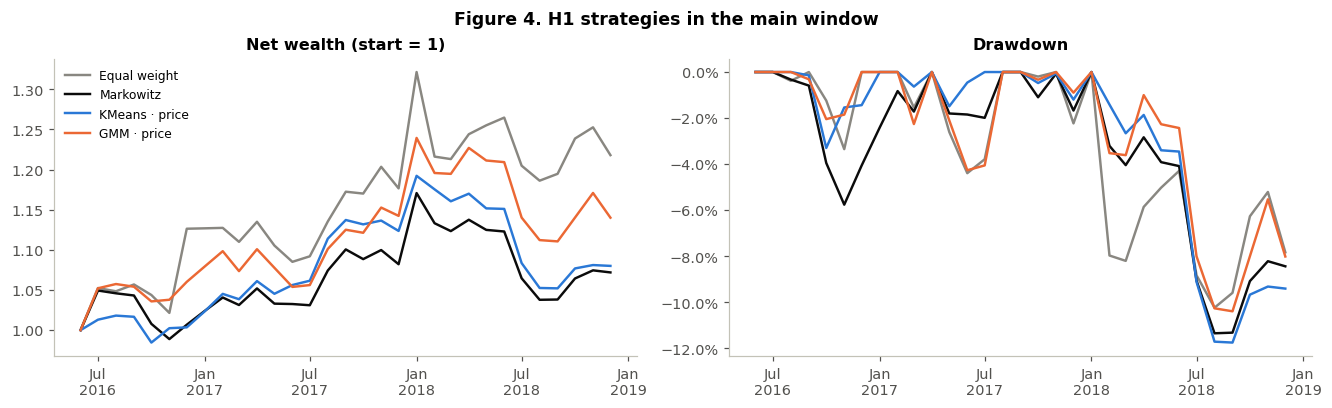

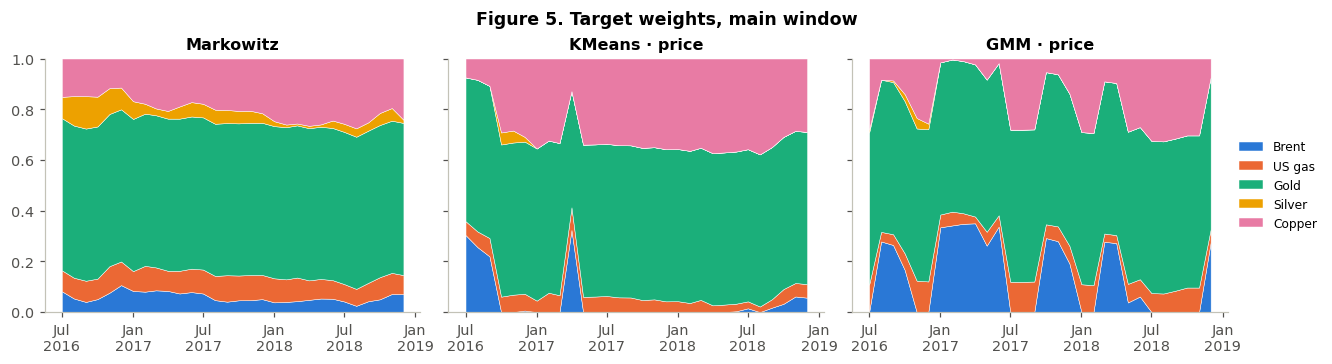

Table 6. Gross return difference with Markowitz by asset, % per year


,Brent,US gas,Gold,Silver,Copper,total
Equal weight,+1.6,+3.3,+0.1,-0.6,+1.1,+5.6
KMeans · price,-1.2,-0.7,-0.2,+0.2,+2.3,+0.3
GMM · price,+0.1,+0.8,-0.0,+0.3,+1.5,+2.7


In [16]:
H1 = ["Equal weight", "Markowitz", "KMeans · price", "GMM · price"]

def with_contrast(exp, names, base="Markowitz"):
    table = perf[exp].loc[names].copy()
    c = contrasts(results[exp]["net"], {s: (s, base) for s in names if s != base})
    table[f"ΔSharpe vs {base} [95%]"] = [f"{c.loc[s, 'ΔSharpe']:+.2f} [{c.loc[s, '95% low']:+.2f}, {c.loc[s, '95% high']:+.2f}]"
                                       if s in c.index else "" for s in names]
    return table

print("Table 5. H1, main window (Jul 2016 - Dec 2018, 30 months), net of 10 bp costs")
show(with_contrast("A", H1), **PCT)

net, W = results["A"]["net"], results["A"]["weights"]
start = net.index[0] - pd.DateOffset(months=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained")
for s in H1:
    wealth = pd.concat([pd.Series({start: 1.0}), (1 + net[s]).cumprod()])
    axes[0].plot(wealth.index, wealth, lw=1.6, label=s, **style(s))
    axes[1].plot(wealth.index, wealth / wealth.cummax() - 1, lw=1.6, label=s, **style(s))
axes[0].set(title="Net wealth (start = 1)")
axes[1].set(title="Drawdown")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=8)
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.suptitle("Figure 4. H1 strategies in the main window", fontweight="bold")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True, layout="constrained")
for ax, s in zip(axes, ["Markowitz", "KMeans · price", "GMM · price"]):
    ax.stackplot(W[s].index, W[s].T.to_numpy(), colors=ASSET_COLORS, labels=W[s].columns, edgecolor="white", linewidth=0.3)
    ax.set(title=s, ylim=(0, 1))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
fig.suptitle("Figure 5. Target weights, main window", fontweight="bold")
plt.show()

def attribution(exp, names, base="Markowitz"):
    """Annualised gross return gained or lost against the base, by asset: 12 x mean((w - w_base) * r), in %."""
    W, r = results[exp]["weights"], ret.loc[EXPERIMENTS[exp]["dates"]]
    out = pd.DataFrame({s: 100 * 12 * ((W[s] - W[base]) * r).mean() for s in names}).T
    out["total"] = out.sum(axis=1)
    return out

print("Table 6. Gross return difference with Markowitz by asset, % per year")
show(attribution("A", ["Equal weight", "KMeans · price", "GMM · price"]), "{:+.1f}")

Both regime strategies finish above Markowitz (Sharpe 0.43 and 0.57, against 0.35) but below equal weight (0.64), and both intervals include zero. Drawdowns are similar for all four strategies (−10% to −12%), all reached in the second half of 2018.

Figure 5 shows how the regimes change decisions. Every optimised portfolio keeps gold at the 60% cap, because gold had the best risk–return trade-off in every ten-year window, so the regimes can only move the remaining 40%. Markowitz spreads that slice over copper, gas, Brent and silver and barely changes it. KMeans holds most of it in copper and occasionally switches a large part into Brent. The GMM moves Brent between 0 and about 35% from one month to the next. This is why regime turnover is 13–25% a month, against 9% for Markowitz.

Table 6 shows what these moves earned. Before costs, the GMM gained 2.7 points a year over Markowitz, mostly from copper (+1.5) and gas (+0.8). KMeans gained only 0.3 points: its copper gains (+2.3) were offset by losses on Brent (−1.2) and gas (−0.7). Equal weight did better than both (+5.6 points), simply by holding more gas and Brent, which Markowitz underweights.

**Conclusion for H1 (main window).** Conditioning on regimes changes the allocation visibly, but the performance difference cannot be distinguished from noise. The additional period (Section 5.1) does not support H1 either.

### 4.3 H2: Does news sentiment improve portfolio allocation?

If sentiment is to help a strategy that trades two months later, it must say something about returns two or more months ahead. Figure 6 shows the correlation between $S_t$ and each commodity's change $r_{t+h}$, from three months before to three months after the news month. The dashed lines mark $\pm1.96/\sqrt{T}$, an approximate band for zero correlation that ignores autocorrelation and is therefore generous.

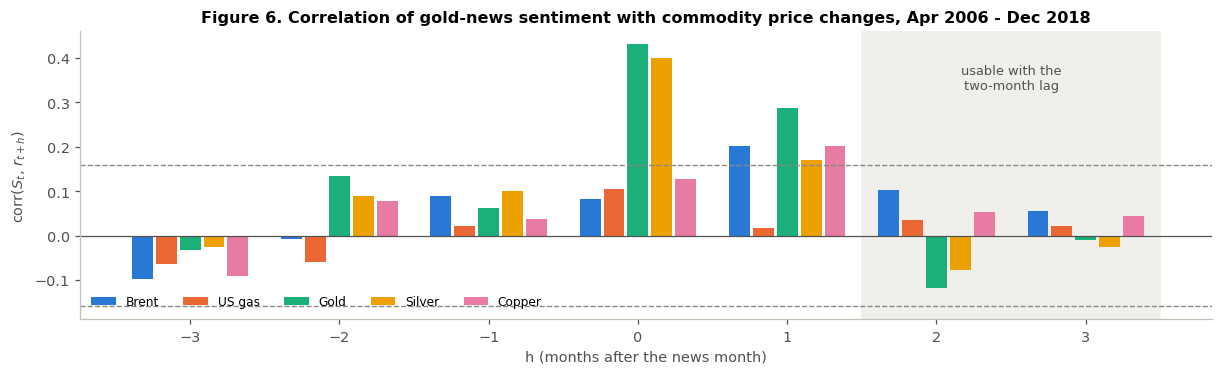

Table 7. H2, main window


,Sharpe,SE (Lo),CAGR,volatility,max drawdown,turnover / month,gold weight,ΔSharpe vs Markowitz [95%]
Markowitz,0.35,0.63,2.8%,9.2%,-11.3%,8.9%,60.0%,
News only,0.20,0.63,1.5%,10.3%,-11.9%,27.6%,59.1%,"-0.15 [-0.49, +0.15]"


Evaluation signals in the high-sentiment state: 33%. Mean |weight difference| with Markowitz (pp): Brent 6.0, US gas 4.4, Gold 0.9, Silver 11.7, Copper 3.9


,Brent,US gas,Gold,Silver,Copper,total
News only,+0.3,-0.5,-0.1,+0.2,-0.7,-0.9


In [17]:
lead_lag = pd.DataFrame({h: {a: sentiment.corr(ret[a].shift(-h).reindex(sentiment.index)) for a in ret.columns}
                         for h in range(-3, 4)}).T
band = 1.96 / np.sqrt(len(sentiment))
fig, ax = plt.subplots(figsize=(11, 3.3), layout="constrained")
for i, (a, color) in enumerate(zip(ret.columns, ASSET_COLORS)):
    ax.bar(lead_lag.index + (i - 2) * 0.16, lead_lag[a], 0.14, color=color, label=a)
ax.axvspan(1.5, 3.5, color="#f0efec", zorder=0)
ax.text(2.5, 0.33, "usable with the\ntwo-month lag", ha="center", fontsize=8.5, color="#52514e")
for b in (band, -band):
    ax.axhline(b, color="#898781", lw=0.9, ls="--")
ax.axhline(0, color="#52514e", lw=0.8)
ax.set(xlabel="h (months after the news month)", ylabel="corr($S_t$, $r_{t+h}$)",
       title="Figure 6. Correlation of gold-news sentiment with commodity price changes, Apr 2006 - Dec 2018")
ax.legend(ncol=5, fontsize=8, loc="lower left")
plt.show()

print("Table 7. H2, main window")
show(with_contrast("A", ["Markowitz", "News only"]), **PCT)
state_share = news_states.loc[EXPERIMENTS["A"]["signals"], 1].mean()
w_diff = 100 * (W["News only"] - W["Markowitz"])
print(f"Evaluation signals in the high-sentiment state: {state_share:.0%}. Mean |weight difference| with Markowitz (pp): "
      + ", ".join(f"{a} {v:.1f}" for a, v in w_diff.abs().mean().items()))
show(attribution("A", ["News only"]), "{:+.1f}")

Sentiment is strongly correlated with gold (0.43) and silver (0.40) in the same month. One month later it is still correlated with gold (0.29), and with Brent and copper (0.20), probably because month $t+1$'s average price still includes part of month $t$'s move. At the usable horizons ($h=2,3$), every correlation is within ±0.12 and inside the band, and the gold correlation even turns negative. The index records how gold has just behaved, which the price data already contain.

In the portfolio, the sentiment states mostly moved silver and Brent (average absolute weight differences of 12 and 6 points), while gold stayed at the cap. These moves tripled turnover (28% a month) and lost 0.9 points a year before costs. The Sharpe ratio fell from 0.35 to 0.20, with an interval of [−0.49, +0.15]. A zero threshold instead of the median gives 0.32, still below Markowitz (Section 5.1).

**Conclusion for H2.** We find no evidence that gold-news sentiment improves the allocation. A likely reason is that, at the horizon we can trade, the index carries almost no information. With 30 months, we cannot exclude a small positive effect.

### 4.4 H3: Does combining regimes and sentiment improve allocation?

Here each regime model is compared with the same model after sentiment is added as a feature. The main contrasts use price-only regimes; the price+FRED versions (as in Notebook 05) and a comparison with the sentiment-only strategy complete the picture. To see *how* sentiment acts, we also report two measures on the 30 evaluation months: whether it changes the regimes (ARI between the two partitions) and whether it changes the portfolio (average distance between target weights, $\tfrac12\sum_i|w_{i,t}-w'_{i,t}|$).

In [18]:
H3 = {"KMeans: price+news vs price": ("KMeans · price+news", "KMeans · price"),
      "GMM: price+news vs price": ("GMM · price+news", "GMM · price"),
      "KMeans: price+FRED+news vs price+FRED": ("KMeans · price+FRED+news", "KMeans · price+FRED"),
      "GMM: price+FRED+news vs price+FRED": ("GMM · price+FRED+news", "GMM · price+FRED"),
      "KMeans: price+news vs news only": ("KMeans · price+news", "News only"),
      "GMM: price+news vs news only": ("GMM · price+news", "News only")}

def pair_table(exp, pairs):
    c = contrasts(results[exp]["net"], pairs)
    sig, W, rows = EXPERIMENTS[exp]["signals"], results[exp]["weights"], {}
    for label, (a, b) in pairs.items():
        ari = (adjusted_rand_score(hard(memberships(exp)[a]).loc[sig], hard(memberships(exp)[b]).loc[sig])
               if b != "News only" else np.nan)
        rows[label] = {"Sharpe (with)": perf[exp].loc[a, "Sharpe"], "Sharpe (without)": perf[exp].loc[b, "Sharpe"],
                       "ΔSharpe": c.loc[label, "ΔSharpe"], "95% low": c.loc[label, "95% low"], "95% high": c.loc[label, "95% high"],
                       "regime ARI": ari, "weight distance": (W[a] - W[b]).abs().sum(axis=1).mean() / 2,
                       "Δ max drawdown": perf[exp].loc[a, "max drawdown"] - perf[exp].loc[b, "max drawdown"]}
    return pd.DataFrame(rows).T

print("Table 8. H3, main window ('with' = first model of each comparison)")
show(pair_table("A", H3), **{"weight distance": "{:.1%}", "Δ max drawdown": "{:+.1%}"})

Table 8. H3, main window ('with' = first model of each comparison)


,Sharpe (with),Sharpe (without),ΔSharpe,95% low,95% high,regime ARI,weight distance,Δ max drawdown
KMeans: price+news vs price,0.34,0.43,-0.08,-0.66,0.23,0.47,4.7%,-0.1%
GMM: price+news vs price,0.02,0.57,-0.56,-1.37,0.09,0.21,14.2%,-2.5%
KMeans: price+FRED+news vs price+FRED,0.16,0.68,-0.52,-1.18,-0.13,0.47,11.4%,-1.0%
GMM: price+FRED+news vs price+FRED,0.41,0.44,-0.03,-0.08,0.01,1.00,1.3%,+0.0%
KMeans: price+news vs news only,0.34,0.20,0.15,-0.29,0.62,–,18.0%,+0.1%
GMM: price+news vs news only,0.02,0.20,-0.18,-1.11,0.49,–,21.1%,-1.1%


Adding sentiment lowers the Sharpe ratio in all four regime comparisons: by 0.08 and 0.56 for the price models, and by 0.52 and 0.03 for the price+FRED models. One interval excludes zero (KMeans · price+FRED, [−1.18, −0.13]), and the other three include it. Against the sentiment-only strategy, the combined models are mixed (+0.15 for KMeans, −0.18 for the GMM). The combination is therefore not better than either source alone.

The last columns show how sentiment acts. For three of the four models, one extra feature is enough to change the regimes substantially (ARI 0.21–0.47 with the model without sentiment). Only for the GMM with FRED do the regimes stay identical (ARI 1.00, weight distance 1%), and that is also the smallest loss. The largest changes in the portfolio come with GMM · price (14% weight distance) and KMeans · price+FRED (11%), the two largest losses. The GMM · price+news model is also the least stable across seeds (minimum ARI 0.27, Table 4), so part of its loss may come from the GMM landing on a different partition rather than from the information in sentiment. Sentiment never reduces the maximum drawdown.

**Conclusion for H3.** Combining regimes and sentiment does not improve on either alone. Sentiment changes the regimes, but not in a way that is related to later returns, which is consistent with the H2 result.

### 4.5 Additional experiment: macroeconomic information

Price-only and price+FRED regimes are fitted on the same months (from April 2006), so the comparison is consistent within each window. We report it for the main window and, separately, for 2021–2025. This window reproduces Notebook 03, whose price-only models were refitted on the common sample for the same reason.

In [19]:
FRED_PAIRS = {"KMeans: price+FRED vs price": ("KMeans · price+FRED", "KMeans · price"),
              "GMM: price+FRED vs price": ("GMM · price+FRED", "GMM · price")}
print("Table 9. FRED increment, each window evaluated separately")
show(pd.concat({f"{exp} ({EXPERIMENTS[exp]['first']:%b %Y} - {EXPERIMENTS[exp]['last']:%b %Y})": pair_table(exp, FRED_PAIRS)
                for exp in EXPERIMENTS}), **{"weight distance": "{:.1%}", "Δ max drawdown": "{:+.1%}"})
print("States of the price+FRED models (fit to Dec 2020):")
show(state_profile([("B", a, "price+FRED") for a in ["KMeans", "GMM"]], ["commodity change, %/m", "VIX", "10y-2y slope"]),
     **{"dev. months": "{:.0f}", "eval. months": "{:.0f}", "VIX": "{:.1f}"})

Table 9. FRED increment, each window evaluated separately


Sharpe (with)  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price          0.68   
                        GMM: price+FRED vs price             0.44   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price          1.04   
                        GMM: price+FRED vs price             0.88   

                                                    Sharpe (without) ΔSharpe  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price             0.43    0.25   
                        GMM: price+FRED vs price                0.57   -0.14   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price             1.04    0.00   
                        GMM: price+FRED vs price                1.11   -0.22   

                                                    95% low 95% high  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price   -0.01     0.55   
                        GMM: price+FRED vs price      -0.67     0.23   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price   -0.18     0.14   
                        GMM: price+FRED vs price      -0.57     0.08   

                                                    regime ARI  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price       0.09   
                        GMM: price+FRED vs price          0.34   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price       0.25   
                        GMM: price+FRED vs price          0.08   

                                                    weight distance  \
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price            7.6%   
                        GMM: price+FRED vs price              11.5%   
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price            7.3%   
                        GMM: price+FRED vs price              17.2%   

                                                    Δ max drawdown  
A (Jul 2016 - Dec 2018) KMeans: price+FRED vs price          +0.6%  
                        GMM: price+FRED vs price             +0.7%  
B (Mar 2021 - Dec 2025) KMeans: price+FRED vs price          -0.0%  
                        GMM: price+FRED vs price             +0.3%

States of the price+FRED models (fit to Dec 2020):


dev. months commodity change, %/m   VIX  \
model                  state                                           
B: KMeans · price+FRED 0              18                 -7.85  33.6   
                       1              15                 -0.21  14.1   
                       2             102                 -0.17  15.9   
                       3              42                  4.46  24.5   
B: GMM · price+FRED    0              20                 -5.56  38.2   
                       1              90                 -0.45  15.1   
                       2              17                  0.89  14.0   
                       3              50                  3.25  22.2   

                             10y-2y slope basket at t+2, dev. % eval. months  \
model                  state                                                   
B: KMeans · price+FRED 0             1.56                 -0.19            1   
                       1            -0.00                  1.22           20   
                       2             1.29                 -0.33           28   
                       3             1.68                  2.80            9   
B: GMM · price+FRED    0             1.62                  0.23            2   
                       1             1.16                 -0.46           23   
                       2             0.01                  0.86            1   
                       3             1.86                  2.42           32   

                             basket at t+2, eval. %  
model                  state                         
B: KMeans · price+FRED 0                      -6.40  
                       1                       1.17  
                       2                       1.61  
                       3                       0.54  
B: GMM · price+FRED    0                      -2.31  
                       1                       0.98  
                       2                       4.83  
                       3                       1.38

In the main window, FRED features help KMeans (+0.25, interval just including zero) and hurt the GMM (−0.14). In 2021–2025 they make no difference for KMeans (+0.00) and hurt the GMM again (−0.22). They change the regimes a lot (ARI 0.08–0.34 with the price-only partitions) and the portfolios moderately (7–17% weight distance), but drawdowns barely move.

The states do take on a macro meaning. Both FRED models create a state with a flat yield curve (slope close to zero, VIX around 14), which price features cannot detect. KMeans and the GMM also agree more with FRED features (ARI 0.51–0.63, against 0.23–0.26 without; Table 4). In 2021–2025, however, the ordering of states by later returns breaks down again: the top KMeans state was followed by +0.5%, against +1.2% to +1.6% for the middle states.

**Conclusion.** FRED indicators make the regimes easier to interpret but not more useful for allocation. One comparison looks favourable: KMeans · price+FRED against Markowitz in 2016–2018 (+0.33, interval [+0.04, +0.81]), the result highlighted in our earlier drafts. We do not count it as evidence. It is one of 19 comparisons, it depends on $k$ (Table 12), and the same model trails Markowitz in 2021–2025 (−0.10).

### 4.6 Summary of hypothesis tests

Table 10. All 19 paired comparisons (Sharpe of the first strategy minus the second)


ΔSharpe  \
hypothesis window  comparison                                                  
H1         2016-18 KMeans · price  vs  Markowitz                       +0.08   
                   GMM · price  vs  Markowitz                          +0.23   
H2         2016-18 News only  vs  Markowitz                            -0.15   
H3         2016-18 KMeans · price+news  vs  KMeans · price             -0.08   
                   GMM · price+news  vs  GMM · price                   -0.56   
                   KMeans · price+FRED+news  vs  KMeans · price+FRED   -0.52   
                   GMM · price+FRED+news  vs  GMM · price+FRED         -0.03   
                   KMeans · price+news  vs  News only                  +0.15   
                   GMM · price+news  vs  News only                     -0.18   
FRED       2016-18 KMeans · price+FRED  vs  KMeans · price             +0.25   
                   GMM · price+FRED  vs  GMM · price                   -0.14   
H1 + FRED  2016-18 KMeans · price+FRED  vs  Markowitz                  +0.33   
                   GMM · price+FRED  vs  Markowitz                     +0.09   
H1         2021-25 KMeans · price  vs  Markowitz                       -0.11   
                   GMM · price  vs  Markowitz                          -0.04   
FRED       2021-25 KMeans · price+FRED  vs  KMeans · price             +0.00   
                   GMM · price+FRED  vs  GMM · price                   -0.22   
H1 + FRED  2021-25 KMeans · price+FRED  vs  Markowitz                  -0.10   
                   GMM · price+FRED  vs  Markowitz                     -0.26   

                                                                        95% interval  \
hypothesis window  comparison                                                          
H1         2016-18 KMeans · price  vs  Markowitz                      [-0.42, +0.74]   
                   GMM · price  vs  Markowitz                         [-0.29, +0.70]   
H2         2016-18 News only  vs  Markowitz                           [-0.49, +0.15]   
H3         2016-18 KMeans · price+news  vs  KMeans · price            [-0.66, +0.23]   
                   GMM · price+news  vs  GMM · price                  [-1.37, +0.09]   
                   KMeans · price+FRED+news  vs  KMeans · price+FRED  [-1.18, -0.13]   
                   GMM · price+FRED+news  vs  GMM · price+FRED        [-0.08, +0.01]   
                   KMeans · price+news  vs  News only                 [-0.29, +0.62]   
                   GMM · price+news  vs  News only                    [-1.11, +0.49]   
FRED       2016-18 KMeans · price+FRED  vs  KMeans · price            [-0.01, +0.55]   
                   GMM · price+FRED  vs  GMM · price                  [-0.67, +0.23]   
H1 + FRED  2016-18 KMeans · price+FRED  vs  Markowitz                 [+0.04, +0.81]   
                   GMM · price+FRED  vs  Markowitz                    [-0.36, +0.43]   
H1         2021-25 KMeans · price  vs  Markowitz                      [-0.40, +0.10]   
                   GMM · price  vs  Markowitz                         [-0.37, +0.29]   
FRED       2021-25 KMeans · price+FRED  vs  KMeans · price            [-0.18, +0.14]   
                   GMM · price+FRED  vs  GMM · price                  [-0.57, +0.08]   
H1 + FRED  2021-25 KMeans · price+FRED  vs  Markowitz                 [-0.37, +0.10]   
                   GMM · price+FRED  vs  Markowitz                    [-0.58, +0.00]   

                                                                                                 reading  
hypothesis window  comparison                                                                             
H1         2016-18 KMeans · price  vs  Markowitz                      inconclusive (interval includes 0)  
                   GMM · price  vs  Markowitz                         inconclusive (interval includes 0)  
H2         2016-18 News only  vs  Markowitz                           inconclusive (interval includes 0)  
H3  

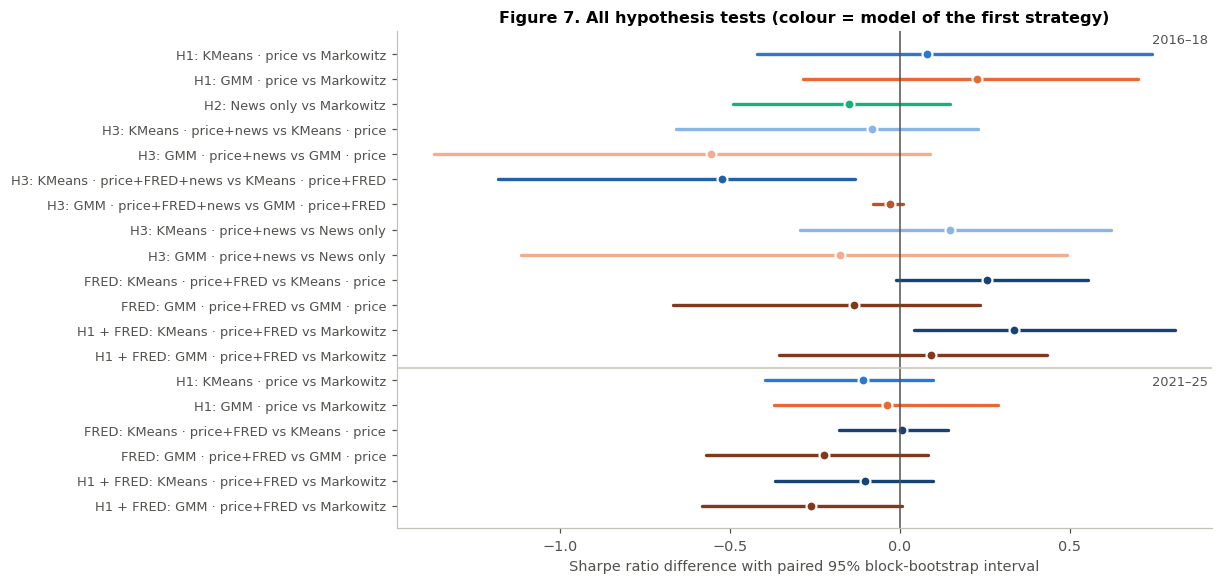

In [20]:
SUMMARY = [("H1", "A", "KMeans · price", "Markowitz"), ("H1", "A", "GMM · price", "Markowitz"),
           ("H2", "A", "News only", "Markowitz"),
           ("H3", "A", "KMeans · price+news", "KMeans · price"), ("H3", "A", "GMM · price+news", "GMM · price"),
           ("H3", "A", "KMeans · price+FRED+news", "KMeans · price+FRED"), ("H3", "A", "GMM · price+FRED+news", "GMM · price+FRED"),
           ("H3", "A", "KMeans · price+news", "News only"), ("H3", "A", "GMM · price+news", "News only"),
           ("FRED", "A", "KMeans · price+FRED", "KMeans · price"), ("FRED", "A", "GMM · price+FRED", "GMM · price"),
           ("H1 + FRED", "A", "KMeans · price+FRED", "Markowitz"), ("H1 + FRED", "A", "GMM · price+FRED", "Markowitz"),
           ("H1", "B", "KMeans · price", "Markowitz"), ("H1", "B", "GMM · price", "Markowitz"),
           ("FRED", "B", "KMeans · price+FRED", "KMeans · price"), ("FRED", "B", "GMM · price+FRED", "GMM · price"),
           ("H1 + FRED", "B", "KMeans · price+FRED", "Markowitz"), ("H1 + FRED", "B", "GMM · price+FRED", "Markowitz")]
rows = []
for h, exp, a, b in SUMMARY:
    c = contrasts(results[exp]["net"], {"x": (a, b)}).iloc[0]
    verdict = ("positive, interval excludes 0" if c["95% low"] > 0 else
               "negative, interval excludes 0" if c["95% high"] < 0 else "inconclusive (interval includes 0)")
    rows.append({"hypothesis": h, "window": "2016-18" if exp == "A" else "2021-25", "comparison": f"{a}  vs  {b}",
                 "ΔSharpe": c["ΔSharpe"], "95% interval": f"[{c['95% low']:+.2f}, {c['95% high']:+.2f}]", "reading": verdict,
                 "_low": c["95% low"], "_high": c["95% high"], "_color": style(a)["color"]})
summary_tests = pd.DataFrame(rows)
print(f"Table 10. All {len(summary_tests)} paired comparisons (Sharpe of the first strategy minus the second)")
show(summary_tests.drop(columns=["_low", "_high", "_color"]).set_index(["hypothesis", "window", "comparison"]), "{:+.2f}")

fig, ax = plt.subplots(figsize=(11, 5.2), layout="constrained")
y = np.arange(len(summary_tests))[::-1]
for yi, (_, r) in zip(y, summary_tests.iterrows()):
    ax.plot([r["_low"], r["_high"]], [yi, yi], color=r["_color"], lw=2.2, solid_capstyle="round")
    ax.plot(r["ΔSharpe"], yi, "o", color=r["_color"], ms=6.5, mec="white", mew=1.4)
ax.axvline(0, color="#52514e", lw=1)
ax.axhline(y[12] - 0.5, color="#c3c2b7", lw=1)
ax.text(ax.get_xlim()[1], y[12] - 0.8, "2021–25 ", ha="right", va="top", fontsize=8.5, color="#52514e")
ax.text(ax.get_xlim()[1], y[0] + 0.3, "2016–18 ", ha="right", va="bottom", fontsize=8.5, color="#52514e")
ax.set_yticks(y, [f"{r.hypothesis}: {r.comparison.replace('  vs  ', ' vs ')}" for r in summary_tests.itertuples()], fontsize=8.5)
ax.set(xlabel="Sharpe ratio difference with paired 95% block-bootstrap interval",
       title="Figure 7. All hypothesis tests (colour = model of the first strategy)")
plt.show()

Of the 19 comparisons, 17 have intervals that include zero. The two exceptions point in opposite directions, and both involve KMeans with FRED features in 2016–2018: this model beats Markowitz (+0.33), and adding sentiment to it hurts (−0.52). At the 95% level, about one interval in 19 would exclude zero by chance, so neither result is strong evidence. No positive result holds in both windows. Every comparison that favours regimes or FRED in 2016–18 changes sign or falls to zero in 2021–25. The only pattern that repeats is negative: adding FRED to the GMM lowered its Sharpe ratio in both windows, although neither interval excludes zero.

## 5. Robustness checks and limitations

### 5.1 Robustness

**Transaction costs.** The same target weights are repriced at 0 and 25 bp.

In [21]:
cost = {}
for exp in EXPERIMENTS:
    for fee in [0, 10, 25]:
        cost[(exp, f"{fee} bp")] = sharpe(pd.DataFrame({s: backtest(w, fee).net for s, w in results[exp]["weights"].items()}))
print("Table 11. Sharpe ratio by cost level")
show(pd.DataFrame(cost).reindex(STRATEGY_ORDER))

Table 11. Sharpe ratio by cost level


A                  B            
                          0 bp 10 bp  25 bp  0 bp 10 bp 25 bp
Equal weight              0.65  0.64   0.63  0.80  0.79  0.78
Markowitz                 0.36  0.35   0.33  1.15  1.14  1.13
KMeans · price            0.45  0.43   0.40  1.05  1.04  1.01
GMM · price               0.60  0.57   0.53  1.12  1.11  1.08
KMeans · price+FRED       0.71  0.68   0.64  1.06  1.04  1.01
GMM · price+FRED          0.47  0.44   0.40  0.90  0.88  0.86
News only                 0.23  0.20   0.15     –     –     –
KMeans · price+news       0.37  0.34   0.30     –     –     –
GMM · price+news          0.05  0.02  -0.03     –     –     –
KMeans · price+FRED+news  0.18  0.16   0.12     –     –     –
GMM · price+FRED+news     0.44  0.41   0.37     –     –     –

Costs barely matter. Going from 0 to 25 bp lowers Sharpe ratios by 0.02–0.08, and the larger drops are for the high-turnover regime and sentiment strategies. No difference with Markowitz changes sign, except for KMeans · price+news, which is essentially zero at every cost level.

**Regime stability and the number of states.** Table 4 showed small, sometimes empty states and seed-sensitive GMMs. Table 12 shows what this means for the portfolios: every regime strategy is rerun with each $k\in\{2,3,4\}$, keeping everything else fixed (\* = the $k$ selected in Table 2).

In [22]:
k_rows = {}
for exp, cfg in EXPERIMENTS.items():
    for fs in cfg["feature_sets"]:
        X = FEATURES[fs].loc[:cfg["last"]]
        dev = X.index[X.index <= cfg["model_end"]]
        W_k = allocate({(alg, k): fit_regimes(X, alg, k, dev) for alg in ["KMeans", "GMM"] for k in K_GRID},
                       cfg["dates"], cfg["model_end"])
        for alg in ["KMeans", "GMM"]:
            k_rows[(exp, fs, alg)] = {f"k={k}": f"{sharpe(backtest(W_k[(alg, k)]).net):.2f}" + ("*" if k == chosen_k[(exp, alg, fs)] else "")
                                      for k in K_GRID}
            k_rows[(exp, fs, alg)]["Markowitz"] = f"{perf[exp].loc['Markowitz', 'Sharpe']:.2f}"
print("Table 12. Sharpe ratio for each number of states")
display(pd.DataFrame(k_rows).T.rename_axis(["window", "features", "model"]))

Table 12. Sharpe ratio for each number of states


k=2    k=3    k=4 Markowitz
window features        model                                
A      price           KMeans   0.28  0.43*   0.69      0.35
                       GMM      0.46   0.56  0.57*      0.35
       price+FRED      KMeans   0.17  0.68*   0.58      0.35
                       GMM      0.44   0.45  0.44*      0.35
       price+news      KMeans   0.14  0.34*   0.31      0.35
                       GMM      0.46   0.47  0.02*      0.35
       price+FRED+news KMeans  0.16*   0.51   0.36      0.35
                       GMM      0.49   0.45  0.41*      0.35
B      price           KMeans   0.95  1.04*   1.23      1.14
                       GMM      1.20   1.21  1.11*      1.14
       price+FRED      KMeans   1.03   0.95  1.04*      1.14
                       GMM      1.12   0.84  0.88*      1.14

This is the most important robustness result. With every other setting fixed, the choice of $k$ moves Sharpe ratios by up to 0.5, more than any effect we are trying to measure. KMeans · price in the main window ranges from 0.28 ($k=2$) to 0.69 ($k=4$), and KMeans · price+FRED+news from 0.16 to 0.51. The latter is Notebook 05's figure, which reused $k=3$ from the model without news instead of applying the selection rule. The rules do not reliably find a good $k$: the selected value is the best in its row for KMeans · price+FRED and the worst for GMM · price+news. In 2021–2025 some unselected values would have beaten Markowitz (KMeans · price with $k=4$, GMM · price with $k=2$ or 3). Choosing them now, however, would amount to selecting on the test period.

The grid also shows that the period matters more than the model. In 2016–2018, 17 of the 24 regime variants beat Markowitz. In 2021–2025, 9 of the 12 fall short of it. In the calm first window almost any departure from the Markowitz allocation helped, equal weight included, whereas in the second window Markowitz's gold-heavy portfolio was hard to beat. Together with the small states in Table 4, this means our regime-conditioned allocations are very sensitive to a hyperparameter that the validation data cannot pin down.

**Bootstrap block length.** Table 13 repeats the comparisons of Table 10 with 3- and 12-month blocks.

In [23]:
blocks = {}
for h, exp, a, b in SUMMARY:
    for bl in [3, 6, 12]:
        c = contrasts(results[exp]["net"], {"x": (a, b)}, block=bl).iloc[0]
        blocks.setdefault((h, "2016-18" if exp == "A" else "2021-25", f"{a} vs {b}"), {})[f"{bl}-month blocks"] = \
            f"{c['ΔSharpe']:+.2f} [{c['95% low']:+.2f}, {c['95% high']:+.2f}]"
print("Table 13. Sharpe differences and 95% intervals for three block lengths")
display(pd.DataFrame(blocks).T.rename_axis(["hypothesis", "window", "comparison"]))

Table 13. Sharpe differences and 95% intervals for three block lengths


3-month blocks  \
hypothesis window  comparison                                                              
H1         2016-18 KMeans · price vs Markowitz                      +0.08 [-0.38, +0.69]   
                   GMM · price vs Markowitz                         +0.23 [-0.30, +0.86]   
H2         2016-18 News only vs Markowitz                           -0.15 [-0.64, +0.24]   
H3         2016-18 KMeans · price+news vs KMeans · price            -0.08 [-0.62, +0.28]   
                   GMM · price+news vs GMM · price                  -0.56 [-1.51, +0.08]   
                   KMeans · price+FRED+news vs KMeans · price+FRED  -0.52 [-1.23, -0.09]   
                   GMM · price+FRED+news vs GMM · price+FRED        -0.03 [-0.09, +0.01]   
                   KMeans · price+news vs News only                 +0.15 [-0.43, +0.85]   
                   GMM · price+news vs News only                    -0.18 [-1.17, +0.67]   
FRED       2016-18 KMeans · price+FRED vs KMeans · price            +0.25 [-0.03, +0.59]   
                   GMM · price+FRED vs GMM · price                  -0.14 [-0.64, +0.23]   
H1 + FRED  2016-18 KMeans · price+FRED vs Markowitz                 +0.33 [+0.06, +0.82]   
                   GMM · price+FRED vs Markowitz                    +0.09 [-0.38, +0.50]   
H1         2021-25 KMeans · price vs Markowitz                      -0.11 [-0.40, +0.11]   
                   GMM · price vs Markowitz                         -0.04 [-0.38, +0.30]   
FRED       2021-25 KMeans · price+FRED vs KMeans · price            +0.00 [-0.18, +0.19]   
                   GMM · price+FRED vs GMM · price                  -0.22 [-0.60, +0.13]   
H1 + FRED  2021-25 KMeans · price+FRED vs Markowitz                 -0.10 [-0.36, +0.09]   
                   GMM · price+FRED vs Markowitz                    -0.26 [-0.58, -0.00]   

                                                                          6-month blocks  \
hypothesis window  comparison                                                              
H1         2016-18 KMeans · price vs Markowitz                      +0.08 [-0.42, +0.74]   
                   GMM · price vs Markowitz                         +0.23 [-0.29, +0.70]   
H2         2016-18 News only vs Markowitz                           -0.15 [-0.49, +0.15]   
H3         2016-18 KMeans · price+news vs KMeans · price            -0.08 [-0.66, +0.23]   
                   GMM · price+news vs GMM · price                  -0.56 [-1.37, +0.09]   
                   KMeans · price+FRED+news vs KMeans · price+FRED  -0.52 [-1.18, -0.13]   
                   GMM · price+FRED+news vs GMM · price+FRED        -0.03 [-0.08, +0.01]   
                   KMeans · price+news vs News only                 +0.15 [-0.29, +0.62]   
                   GMM · price+news vs News only                    -0.18 [-1.11, +0.49]   
FRED       2016-18 KMeans · price+FRED vs KMeans · price            +0.25 [-0.01, +0.55]   
                   GMM · price+FRED vs GMM · price                  -0.14 [-0.67, +0.23]   
H1 + FRED  2016-18 KMeans · price+FRED vs Markowitz                 +0.33 [+0.04, +0.81]   
                   GMM · price+FRED vs Markowitz                    +0.09 [-0.36, +0.43]   
H1         2021-25 KMeans · price vs Markowitz                      -0.11 [-0.40, +0.10]   
                   GMM · price vs Markowitz                         -0.04 [-0.37, +0.29]   
FRED       2021-25 KMeans · price+FRED vs KMeans · price            +0.00 [-0.18, +0.14]   
                   GMM · price+FRED vs GMM · price                  -0.22 [-0.57, +0.08]   
H1 + FRED  2021-25 KMeans · price+FRED vs Markowitz                 -0.10 [-0.37, +0.10]   
                   GMM · price+FRED vs Markowitz                    -0.26 [-0.58, +0.00]   

                                                                         12-month blocks  
hypothesis window  comparison                                                             
H1         2016-18 KMeans 

Block length changes the width of the intervals but not the reading. The two comparisons that exclude zero with six-month blocks do so for all three lengths. With 3- and 12-month blocks, one more crosses the line: GMM · price+FRED against Markowitz in 2021–2025, whose upper bound moves from +0.00 to just below zero. GMM · price+news against GMM · price comes close with 12-month blocks ([−1.41, +0.01]). Both borderline cases go against the richer model.

**Additional evaluation period, 2021–2025 (H1 and FRED).** The news data stop in 2018, so H2 and H3 cannot be tested here.

Table 14. Additional period (Mar 2021 - Dec 2025, 58 months), net of 10 bp costs


,Sharpe,SE (Lo),CAGR,volatility,max drawdown,turnover / month,gold weight,ΔSharpe vs Markowitz [95%]
Equal weight,0.79,0.46,13.0%,17.4%,-25.3%,7.3%,20.0%,"-0.35 [-1.09, +0.31]"
Markowitz,1.14,0.47,13.7%,11.9%,-17.1%,6.1%,59.7%,
KMeans · price,1.04,0.46,13.3%,12.9%,-16.6%,16.3%,56.6%,"-0.11 [-0.40, +0.10]"
GMM · price,1.11,0.47,14.5%,13.1%,-19.4%,18.7%,57.9%,"-0.04 [-0.37, +0.29]"
KMeans · price+FRED,1.04,0.47,13.4%,12.9%,-16.6%,18.9%,57.1%,"-0.10 [-0.37, +0.10]"
GMM · price+FRED,0.88,0.46,10.8%,12.5%,-19.1%,17.3%,54.0%,"-0.26 [-0.58, +0.00]"


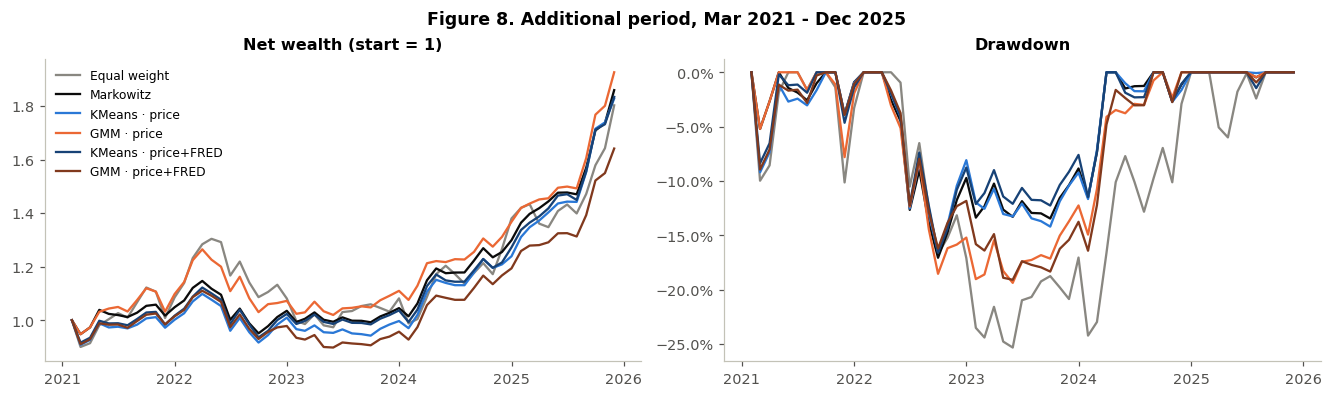

Gross return difference with Markowitz by asset, % per year:


,Brent,US gas,Gold,Silver,Copper,total
Equal weight,+1.2,+3.6,-7.5,+3.4,-0.5,+0.2
KMeans · price,+0.5,-0.9,+0.2,+1.0,-0.9,-0.1
GMM · price,+0.9,-0.0,-0.3,+1.1,-0.6,+1.0
KMeans · price+FRED,+0.6,-0.4,-0.1,+0.3,-0.4,-0.0
GMM · price+FRED,+0.1,-0.5,-1.0,-0.1,-0.8,-2.4


In [24]:
print("Table 14. Additional period (Mar 2021 - Dec 2025, 58 months), net of 10 bp costs")
show(with_contrast("B", list(results["B"]["net"])), **PCT)

net_b = results["B"]["net"]
start = net_b.index[0] - pd.DateOffset(months=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
for s in net_b:
    wealth = pd.concat([pd.Series({start: 1.0}), (1 + net_b[s]).cumprod()])
    axes[0].plot(wealth.index, wealth, lw=1.5, label=s, **style(s))
    axes[1].plot(wealth.index, wealth / wealth.cummax() - 1, lw=1.5, **style(s))
axes[0].set(title="Net wealth (start = 1)")
axes[1].set(title="Drawdown")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=8)
fig.suptitle("Figure 8. Additional period, Mar 2021 - Dec 2025", fontweight="bold")
plt.show()
print("Gross return difference with Markowitz by asset, % per year:")
show(attribution("B", [s for s in net_b if s != "Markowitz"]), "{:+.1f}")

In 2021–2025, Markowitz is hard to beat. Its large gold position paid off during the gold rally: its Sharpe ratio is 1.14, against 0.79 for equal weight, which suffered a −25% drawdown after the 2022 energy peak. All four regime strategies fall behind Markowitz (−0.04 to −0.26), and none improves the maximum drawdown by more than half a point. They again trade much more (16–19% a month, against 6%). Before costs they stay within one point a year of Markowitz, except GMM · price+FRED, which lost 2.4 points by holding less gold (54% on average) during the rally. This window reproduces Notebook 03 exactly. Its main lesson is that the H1 differences seen in 2016–2018 do not carry over.

**Other checks.** (i) A zero threshold for the sentiment states instead of the development median. (ii) Price-only regimes in 2021–2025 trained from January 2001, the longer sample used in Notebooks 01–02.

In [25]:
W0 = allocate({"zero": pd.DataFrame(np.eye(2)[(sentiment > 0).astype(int)], index=sentiment.index)},
              EXPERIMENTS["A"]["dates"], EXPERIMENTS["A"]["model_end"])
print(f"News only with a zero threshold: Sharpe {sharpe(backtest(W0['zero']).net):.2f} "
      f"(median threshold {perf['A'].loc['News only', 'Sharpe']:.2f}, Markowitz {perf['A'].loc['Markowitz', 'Sharpe']:.2f})")
cfg = EXPERIMENTS["B"]
X01 = price_feat.dropna()
k01, _ = select_k(X01, X01.index[X01.index <= cfg["train_end"]],
                  X01.index[(X01.index > cfg["train_end"]) & (X01.index <= cfg["model_end"])])
W01 = allocate({alg: fit_regimes(X01, alg, k01[alg], X01.index[X01.index <= cfg["model_end"]]) for alg in ["KMeans", "GMM"]},
               cfg["dates"], cfg["model_end"])
print(f"2021-25, price-only regimes trained from Jan 2001 (k = {k01}): "
      + ", ".join(f"{s} {sharpe(backtest(W01[s]).net):.2f}" for s in ["Markowitz", "KMeans", "GMM"]))

News only with a zero threshold: Sharpe 0.32 (median threshold 0.20, Markowitz 0.35)
2021-25, price-only regimes trained from Jan 2001 (k = {'KMeans': 3, 'GMM': 4}): Markowitz 1.14, KMeans 1.05, GMM 1.12


With a zero threshold, the news-only Sharpe ratio rises to 0.32, still below Markowitz (0.35). Training the price-only regimes from 2001, as in Notebooks 01–02, gives 1.05 (KMeans) and 1.12 (GMM) in 2021–2025, against 1.04 and 1.11 on the common sample. Starting the sample in 2006 therefore does not drive the results.

### 5.2 Methodological limitations

**Revised data and point-in-time availability.** All inputs are recent snapshots and may contain later revisions. The broad dollar index `DTWEXBGS` uses a methodology introduced in February 2019 and back-filled to 2006 (von Beschwitz et al., 2019), so the FRED models in the main window use a series that did not exist at the time. The news labels were assigned after the fact, and a headline's date does not prove when it, or its label, became available. The two-month lag handles publication delays but not these issues. These problems can only help the strategies that use the affected data (FRED and news). They therefore strengthen our negative conclusions for these sources, while any positive result should be discounted.

**Monthly average prices versus investable returns.** World Bank series are monthly averages of benchmark prices. They miss futures roll yield, collateral return and executable prices, and averaging smooths volatility. Costs are a proportional fee, not measured trading costs. This affects the *levels* (a tradable futures portfolio would have different Sharpe ratios) more than the *comparisons*, since all strategies use the same returns, but none of the numbers is an investable performance.

**Limited news coverage.** The index covers only gold, uses only the supplied labels and is mostly backward-looking. Our negative H2 and H3 results apply to this index, not to news-based signals in general.

**Short evaluation periods.** Thirty and 58 months give Sharpe-ratio standard errors of about 0.6 and 0.5, larger than most differences between strategies. Our intervals rely on few bootstrap blocks and hold the fitted models fixed. "Inconclusive" therefore often means that the test has little power, not that the effect is zero.

**Model-selection uncertainty and research selection.** Results depend strongly on $k$, which the validation data cannot pin down (Table 12), and the GMM depends on its initialisation. We did not vary risk aversion, the cap, the shrinkage or the window, and we did not try models of regime transitions such as hidden Markov models. Both windows were examined in earlier stages of the project, and this design was set after those results were known. The evaluations are chronological, so no future data enter any decision, but they are not untouched hold-out samples, and the 19 intervals are not adjusted for multiple comparisons.

## 6. Discussion and conclusion

**What we learned about market regimes.** Clustering months on price features gives states that make economic sense (sell-offs, calm markets, rallies) and that stay similar when the models are refitted on more data. In the development years, these states were followed by different returns, in a momentum-like pattern. That pattern was not reliable out of sample, and the clusters are weak: low silhouettes, disagreement between KMeans and the GMM, near-empty states and seed-dependent GMM solutions. Together with the gold cap and the shrinkage towards unconditional moments, this left regimes able to move only a fraction of the portfolio, and not in a consistently useful direction.

**Did news sentiment add value?** No. The gold-news index mostly describes the same month's price moves, so at the two-month horizon we can trade it carries little information. The sentiment-only strategy traded much more than Markowitz and earned less.

**Did combining sources help?** No. Adding sentiment to a regime model changed its states and lowered its Sharpe ratio in all four comparisons. Adding FRED made the regimes easier to interpret but did not improve the portfolios.

**What is robust and what is not.** Several findings hold in both windows and do not depend on costs or block length: the gold-at-cap structure of every optimised portfolio, the higher turnover of conditioned strategies, the weak separation of the clusters and the instability of the GMM. The negative sign of the sentiment effect is consistent across all four comparisons, although only one interval excludes zero. The sign of the regime effect is not robust: it depends on the window and on $k$. The two intervals that exclude zero involve the same model in the same window and are consistent with chance.

**Next step.** Sample size limits everything we can conclude. The most useful next step would be a longer evaluation on investable futures returns, using point-in-time data, with the contrasts and $k$ fixed in advance and dates that we have not yet examined. For news, the natural extension is a forward-looking index, built for example from the 3% of headlines that look ahead, together with coverage of the other four commodities.

## 7. References and contributions

**References**

* Lo, A. W. (2002). The statistics of Sharpe ratios. *Financial Analysts Journal*, 58(4), 36–52.
* Sinha, A. and Khandait, T. (2020). Impact of news on the commodity market: dataset and results. [arXiv:2009.04202](https://arxiv.org/abs/2009.04202). Data: [SaguaroCapital/sentiment-analysis-in-commodity-market-gold](https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold), revision `4423810`.
* von Beschwitz, B., Collins, C. G. and Datta, D. D. (2019). [Revisions to the Federal Reserve dollar indexes](https://www.federalreserve.gov/econres/notes/feds-notes/revisions-to-the-federal-reserve-dollar-indexes-20190115.html). FEDS Notes.
* Working, H. (1960). Note on the correlation of first differences of averages in a random chain. *Econometrica*, 28(4), 916–918.
* World Bank, [Commodity Markets (Pink Sheet)](https://www.worldbank.org/en/research/commodity-markets). FRED, Federal Reserve Bank of St. Louis: [VIXCLS](https://fred.stlouisfed.org/series/VIXCLS), [DTWEXBGS](https://fred.stlouisfed.org/series/DTWEXBGS), [DGS10](https://fred.stlouisfed.org/series/DGS10), [DGS2](https://fred.stlouisfed.org/series/DGS2).
* Champonnois, S. *Machine Learning for Portfolio Management and Trading*, course notebooks ([skfin](https://github.com/schampon/skfin/tree/master/nbs)): `10_Mean_variance_estimators`, `11_Backtesting`, `30_Transaction_cost`, `41_Timing_backtest_with_learning`, `46_Text_processing`.

**Contributions.** **Ons Jdey** assembled and documented the World Bank and FRED data and developed the price features, the KMeans and GMM regime models and their diagnostics. Ons also built the regime-conditioned Markowitz engine with costs and the paired bootstrap, and ran the FRED extension on 2021–2025 (project Notebooks 01–03). **Senghak Rou** built the gold-news cleaning and the sentiment index, the combined regime and sentiment experiment on 2016–2018, the hypothesis tests, the lead–lag analysis and the look-ahead checks (Notebooks 04–05 and the first draft). This notebook merges both lines of work into one design. The earlier notebooks remain in the project repository.

**Relation to earlier notebooks.** The 2021–2025 results reproduce Notebook 03 exactly, and the 2001-sample check reproduces Notebook 02. In the main window, equal weight, Markowitz, news only, KMeans · price+FRED and both GMM price+FRED strategies reproduce Notebook 05. Two methodological points were changed. (1) Our earlier draft tested H1 with price+FRED regimes, which mixed the regime question with the FRED question. H1 now uses price-only regimes, and FRED is tested separately. (2) Notebook 05 reused $k=3$ for KMeans · price+FRED+news. The common selection rule gives $k=2$, and both values are reported in Table 12.

**Reproducibility.** All data are retrieved by the notebook itself. Files are read from the project repository when the notebook is run inside it, and otherwise downloaded from pinned revisions: GitHub commit `3eaa7f3` for the World Bank and FRED snapshots (retrieved 7 November 2026) and Hugging Face revision `4423810` for the news. Every file is checked against its SHA-256 hash. Random seeds are fixed (42 for models and bootstrap). Versions used for the saved run: Python 3.12, numpy 2.4.4, pandas 2.3.3, scipy 1.17.1, scikit-learn 1.9.0, matplotlib 3.10.9, openpyxl 3.1.5, pyarrow 25.0.1, requests 2.34.2.